# Imports

## Import the folder for compatibility (if running local)

In [1]:
import os
import sys

project_root = "Incremental-Learning-MycroftMinds"
cwd = os.path.abspath(os.getcwd())
while True:
    if os.path.basename(cwd) == project_root:
        if cwd not in sys.path:
            sys.path.insert(0, cwd)
        break
    parent = os.path.dirname(cwd)
    if parent == cwd:
        raise FileNotFoundError(f"Project root '{project_root}' not found in any parent directory.")
    cwd = parent

## Import external libs and internal models

In [2]:
import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.notebook import tqdm

from src.data.io import load_dataset
from src.utils.memory import calculate_memory_usage
from src.utils.utils import get_device_data
from src.evaluation.metrics import calculate_metrics, all_time_aggregation_metrics
from src.evaluation.visualization import plot_part_predictions, plot_hourly_predictions
from src.evaluation.training import all_valid_splits_seq_fit_predict, test_set_seq_fit_predict

from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from river.forest import ARFRegressor
from river.tree import HoeffdingTreeRegressor
from src.evaluation.baseline import PreviousValueRegressor, SeasonalMeanRegressor
from src.trees import fastodt
from src.bagging import ARFRegressorFODT
from src.boosting import IncubationBoost
from src.ensemble_methods import elasticGBDT

import ipywidgets as widgets
widgets.IntSlider()

IntSlider(value=0)

# Download the splitted data

In [3]:
# check you data dir and file prefixes
data_dir = '../../data/first_batch'

## Evaluation Settings

## 15-minutes granularity

In [4]:
DATA_FREQUENCY = '15min'
FORECAST_HORIZON = '1h'
SPIKE_PROMINENCE = 9  # Prominence for spike detection, adjusted after EDA
USE_RESIDUAL = False  # Whether to use residual modeling

In [ ]:
# Measure loading time
start_time = time.time()

# Load data
train, valid, test = load_dataset(data_dir=data_dir, prefix='dev_4_15m_new_wfv', use_numpy=True)
ALL_FEATURES = ['time', 'device_id', 'hour', 'weekday', 'month', 
            'L1_act_power_lag_15min', 'L1_act_power_lag_1h', 'L1_act_power_lag_24h', 
            'L1_app_power_lag_15min', 'L1_app_power_lag_1h', 'L1_app_power_lag_24h', 
            'L1_current_lag_15min', 'L1_current_lag_1h', 'L1_current_lag_24h', 
            'L1_react_power_lag_15min', 'L1_react_power_lag_1h', 'L1_react_power_lag_24h', 
            'L1_voltage_lag_15min', 'L1_voltage_lag_1h', 'L1_voltage_lag_24h', 
            'L2_act_power_lag_15min', 'L2_act_power_lag_1h', 'L2_act_power_lag_24h', 
            'L2_app_power_lag_15min', 'L2_app_power_lag_1h', 'L2_app_power_lag_24h', 
            'L2_current_lag_15min', 'L2_current_lag_1h', 'L2_current_lag_24h', 
            'L2_react_power_lag_15min', 'L2_react_power_lag_1h', 'L2_react_power_lag_24h', 
            'L2_voltage_lag_15min', 'L2_voltage_lag_1h', 'L2_voltage_lag_24h', 
            'L3_act_power_lag_15min', 'L3_act_power_lag_1h', 'L3_act_power_lag_24h',
            'L3_app_power_lag_15min', 'L3_app_power_lag_1h', 'L3_app_power_lag_24h', 
            'L3_current_lag_15min', 'L3_current_lag_1h', 'L3_current_lag_24h', 
            'L3_react_power_lag_15min', 'L3_react_power_lag_1h', 'L3_react_power_lag_24h', 
            'L3_voltage_lag_15min', 'L3_voltage_lag_1h', 'L3_voltage_lag_24h', 
            'grid_freq_lag_15min', 'grid_freq_lag_1h', 'grid_freq_lag_24h', 
            'powerfactor1_lag_15min', 'powerfactor1_lag_1h', 'powerfactor1_lag_24h', 
            'powerfactor2_lag_15min', 'powerfactor2_lag_1h', 'powerfactor2_lag_24h', 
            'powerfactor3_lag_15min', 'powerfactor3_lag_1h', 'powerfactor3_lag_24h']
ALL_FEATURES = ['time', 'device_id', 'hour', 'weekday', 'month', 
            'L1_act_power_lag_1h', 'L1_act_power_lag_24h', 'L1_act_power_lag_1455min', 'L1_act_power_lag_168h', 
            'L1_app_power_lag_1h', 'L1_app_power_lag_24h', 'L1_app_power_lag_1455min', 'L1_app_power_lag_168h', 
            'L1_current_lag_1h', 'L1_current_lag_24h', 'L1_current_lag_1455min', 'L1_current_lag_168h', 
            'L1_react_power_lag_1h', 'L1_react_power_lag_24h', 'L1_react_power_lag_1455min', 'L1_react_power_lag_168h', 
            'L1_voltage_lag_1h', 'L1_voltage_lag_24h', 'L1_voltage_lag_1455min', 'L1_voltage_lag_168h', 
            'L2_act_power_lag_1h', 'L2_act_power_lag_24h', 'L2_act_power_lag_1455min', 'L2_act_power_lag_168h', 
            'L2_app_power_lag_1h', 'L2_app_power_lag_24h', 'L2_app_power_lag_1455min', 'L2_app_power_lag_168h', 
            'L2_current_lag_1h', 'L2_current_lag_24h', 'L2_current_lag_1455min', 'L2_current_lag_168h', 
            'L2_react_power_lag_1h', 'L2_react_power_lag_24h', 'L2_react_power_lag_1455min', 'L2_react_power_lag_168h', 
            'L2_voltage_lag_1h', 'L2_voltage_lag_24h', 'L2_voltage_lag_1455min', 'L2_voltage_lag_168h', 
            'L3_act_power_lag_1h', 'L3_act_power_lag_24h', 'L3_act_power_lag_1455min', 'L3_act_power_lag_168h', 
            'L3_app_power_lag_1h', 'L3_app_power_lag_24h', 'L3_app_power_lag_1455min', 'L3_app_power_lag_168h', 
            'L3_current_lag_1h', 'L3_current_lag_24h', 'L3_current_lag_1455min', 'L3_current_lag_168h', 
            'L3_react_power_lag_1h', 'L3_react_power_lag_24h', 'L3_react_power_lag_1455min', 'L3_react_power_lag_168h', 
            'L3_voltage_lag_1h', 'L3_voltage_lag_24h', 'L3_voltage_lag_1455min', 'L3_voltage_lag_168h', 
            'grid_freq_lag_1h', 'grid_freq_lag_24h', 'grid_freq_lag_1455min', 'grid_freq_lag_168h', 
            'powerfactor1_lag_1h', 'powerfactor1_lag_24h', 'powerfactor1_lag_1455min', 'powerfactor1_lag_168h', 
            'powerfactor2_lag_1h', 'powerfactor2_lag_24h', 'powerfactor2_lag_1455min', 'powerfactor2_lag_168h', 
            'powerfactor3_lag_1h', 'powerfactor3_lag_24h', 'powerfactor3_lag_1455min', 'powerfactor3_lag_168h']

loading_time = time.time() - start_time
print(f"Data loaded in {loading_time/60:.2f} minutes")

[INFO] Loading train data...
[INFO] Train data loaded: 6 samples
[INFO] Loading valid data...
[INFO] Valid data loaded: 6 samples
[INFO] Loading test data...
[INFO] Test data loaded: 2 samples
Data loaded in 0.01 minutes


## Data structure information

The data structure is as follows:
- For walk-forward validation:
  - `train` is a list of tuples, where each tuple is (X, y) for one split
  - `valid` is a list of tuples, where each tuple is (X, y) for one split
  - `test` is a tuple of (X, y)
- Each X array contains:
  - Column 0: `time` (`pandas.Timedelta`)
  - Column 1: `device_id` (`str`)
  - Other columns: time-related features and lag features

The memory usage of the loaded data is printed below:

In [6]:
# Print data structure and memory usage information
if isinstance(train, list):
    print(f"Training data: {len(train)} splits")
    print(f"Validation data: {len(valid)} splits")
    
    # Show first split shape
    print(f"First train split shape: X={train[0][0].shape}, y={train[0][1].shape}")
    print(f"First valid split shape: X={valid[0][0].shape}, y={valid[0][1].shape}")
    
    # Memory usage
    train_mem = sum(calculate_memory_usage(ts) for ts in train)
    valid_mem = sum(calculate_memory_usage(vs) for vs in valid)
    test_mem = calculate_memory_usage(test)
    
    print(f"\nMemory usage:")
    print(f"Train: {train_mem:.2f} MB")
    print(f"Valid: {valid_mem:.2f} MB")
    print(f"Test: {test_mem:.2f} MB")
    print(f"Total: {train_mem + valid_mem + test_mem:.2f} MB")
else:
    # For non-list structure
    print(f"Training data shape: X={train[0].shape}, y={train[1].shape}")
    print(f"Validation data shape: X={valid[0].shape}, y={valid[1].shape}")
    print(f"Test data shape: X={test[0].shape}, y={test[1].shape}")

Training data: 6 splits
Validation data: 6 splits
First train split shape: X=(2687, 81), y=(2687,)
First valid split shape: X=(2688, 81), y=(2688,)

Memory usage:
Train: 35.31 MB
Valid: 10.07 MB
Test: 3.04 MB
Total: 48.43 MB


# WFV Model Evaluation
(train+valid WFV)
- (1) `train[0]` vs `valid[0]`
- (2) `train[1]` vs `valid[1]`
- ...
- (n) `train[n]` vs `valid[n]`

, where: 
$$ train[1] = train[0]+valid[0] $$
$$...$$
$$ train[n] = train[0]+valid[0]+valid[1]+...+valid[n-1] $$

### Baseline model (seasonal averages)

In [7]:
update_freq = "14D"
bl_mean = SeasonalMeanRegressor
bl_mean_params = {}

In [ ]:
bl_mean_train_period_predictions, bl_mean_valid_period_predictions,\
bl_mean_train_period_metrics, bl_mean_valid_period_metrics = all_valid_splits_seq_fit_predict(
    model_class=bl_mean,
    model_params=bl_mean_params,
    train=train,
    valid=valid,
    use_residuals=USE_RESIDUAL,
    incremental=False,
    data_freq=DATA_FREQUENCY,
    forecast_horizon=FORECAST_HORIZON,
    features=ALL_FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE,
    start_split=0,
    verbose=True
)

Processing splits:   0%|          | 0/6 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2022-09-26 14:15:00+02:00 to 2022-10-24 13:45:00+02:00

Time: 0.01 seconds
Predicting for chunk from 2022-10-24 14:00:00+02:00 to 2022-11-07 13:00:00+01:00

-------------------------

Retraining model on data from 2022-09-26 14:15:00+02:00 to 2022-11-07 13:00:00+01:00

Time: 0.01 seconds
Predicting for chunk from 2022-11-07 13:15:00+01:00 to 2022-11-21 12:45:00+01:00

-------------------------
Model's memory usage: 0.024628 MB
Metrics for Device: df_TRB145-4 | Period: 2022-10-24 14:00:00+02:00 - 2022-11-21 12:45:00+01:00
15min Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.4650
	MAE: 0.3398
	MAPE: 38.1012%

Directional Metrics:
	Directional Accuracy: 14.2538%
	First-Diff Correlation: 0.0654

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0526
		Recall: 0.0556
		F1: 0.0541
	Drops:
		Precision: 0.1000
		Recall: 0.1053
		F1: 0.1026

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay

Processing devices in split 1:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2022-09-26 14:15:00+02:00 to 2022-11-21 12:45:00+01:00

Time: 0.01 seconds
Predicting for chunk from 2022-11-21 13:00:00+01:00 to 2022-12-05 13:00:00+01:00

-------------------------

Retraining model on data from 2022-09-26 14:15:00+02:00 to 2022-12-05 13:00:00+01:00

Time: 0.02 seconds
Predicting for chunk from 2022-12-05 13:15:00+01:00 to 2022-12-19 12:45:00+01:00

-------------------------
Model's memory usage: 0.024490 MB
Metrics for Device: df_TRB145-4 | Period: 2022-11-21 13:00:00+01:00 - 2022-12-19 12:45:00+01:00
15min Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.3660
	MAE: 0.2795
	MAPE: 63.3203%

Directional Metrics:
	Directional Accuracy: 14.2538%
	First-Diff Correlation: 0.1272

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay

Processing devices in split 2:   0%|          | 0/1 [00:00<?, ?it/s]

... (3 outputs left out)

Processing devices in split 4:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2022-09-26 14:15:00+02:00 to 2023-02-13 12:45:00+01:00

Time: 0.03 seconds
Predicting for chunk from 2023-02-13 13:00:00+01:00 to 2023-02-27 13:00:00+01:00

-------------------------

Retraining model on data from 2022-09-26 14:15:00+02:00 to 2023-02-27 13:00:00+01:00

Time: 0.02 seconds
Predicting for chunk from 2023-02-27 13:15:00+01:00 to 2023-03-13 12:45:00+01:00

-------------------------
Model's memory usage: 0.024422 MB
Metrics for Device: df_TRB145-4 | Period: 2023-02-13 13:00:00+01:00 - 2023-03-13 12:45:00+01:00
15min Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.3147
	MAE: 0.2255
	MAPE: 68.2034%

Directional Metrics:
	Directional Accuracy: 13.5095%
	First-Diff Correlation: 0.2088

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay

Processing devices in split 5:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2022-09-26 14:15:00+02:00 to 2023-03-13 12:45:00+01:00

Time: 0.04 seconds
Predicting for chunk from 2023-03-13 13:00:00+01:00 to 2023-03-27 14:00:00+02:00

-------------------------

Retraining model on data from 2022-09-26 14:15:00+02:00 to 2023-03-27 14:00:00+02:00

Time: 0.03 seconds
Predicting for chunk from 2023-03-27 14:15:00+02:00 to 2023-04-10 05:30:00+02:00

-------------------------
Model's memory usage: 0.024399 MB
Metrics for Device: df_TRB145-4 | Period: 2023-03-13 13:00:00+01:00 - 2023-04-10 05:30:00+02:00
15min Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.3289
	MAE: 0.2194
	MAPE: 58.5771%

Directional Metrics:
	Directional Accuracy: 13.6021%
	First-Diff Correlation: 0.1276

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.1579
		Recall: 0.1200
		F1: 0.1364
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay

#### Results

In [9]:
print("\n\nValid period metrics:")
bl_mean_all_time_valid_metrics = all_time_aggregation_metrics(bl_mean_valid_period_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Valid period metrics:


Aggregated Metrics Across Periods
Device ID: df_TRB145-4
--------------------------------------------------
15min Metrics:
	RMSE: 0.3508 ± 0.0542
	MAE: 0.2517 ± 0.0458
	MAPE: 58.5581% ± 9.9370%

	Directional Metrics:
		Directional Accuracy: 14.7034% ± 1.4352%
		First-Diff Correlation: 0.1562 ± 0.0545

	Immediate Detection (delta=0):
		Spike Precision: 0.0614 ± 0.0562
		Spike Recall: 0.0570 ± 0.0473
		Spike F1: 0.0588 ± 0.0507
		Drop Precision: 0.0167 ± 0.0373
		Drop Recall: 0.0175 ± 0.0392
		Drop F1: 0.0171 ± 0.0382

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.1579 ± 0.0912
		Spike Recall: 0.1519 ± 0.0860
		Spike F1: 0.1541 ± 0.0870
		Drop Precision: 0.0509 ± 0.0509
		Drop Recall: 0.0484 ± 0.0491
		Drop F1: 0.0493 ± 0.0495
Hourly Metrics:
	RMSE: 0.3351 ± 0.0543
	MAE: 0.2418 ± 0.0469
	MAPE: 53.8213% ± 8.0731%

	Directional Metrics:
		Directional Accuracy: 63.4043% ± 6.3873%
		First-Diff Correlation: 0.5955 ± 0.1261

	Immediate Detection (delta=0):

#### Validation plots

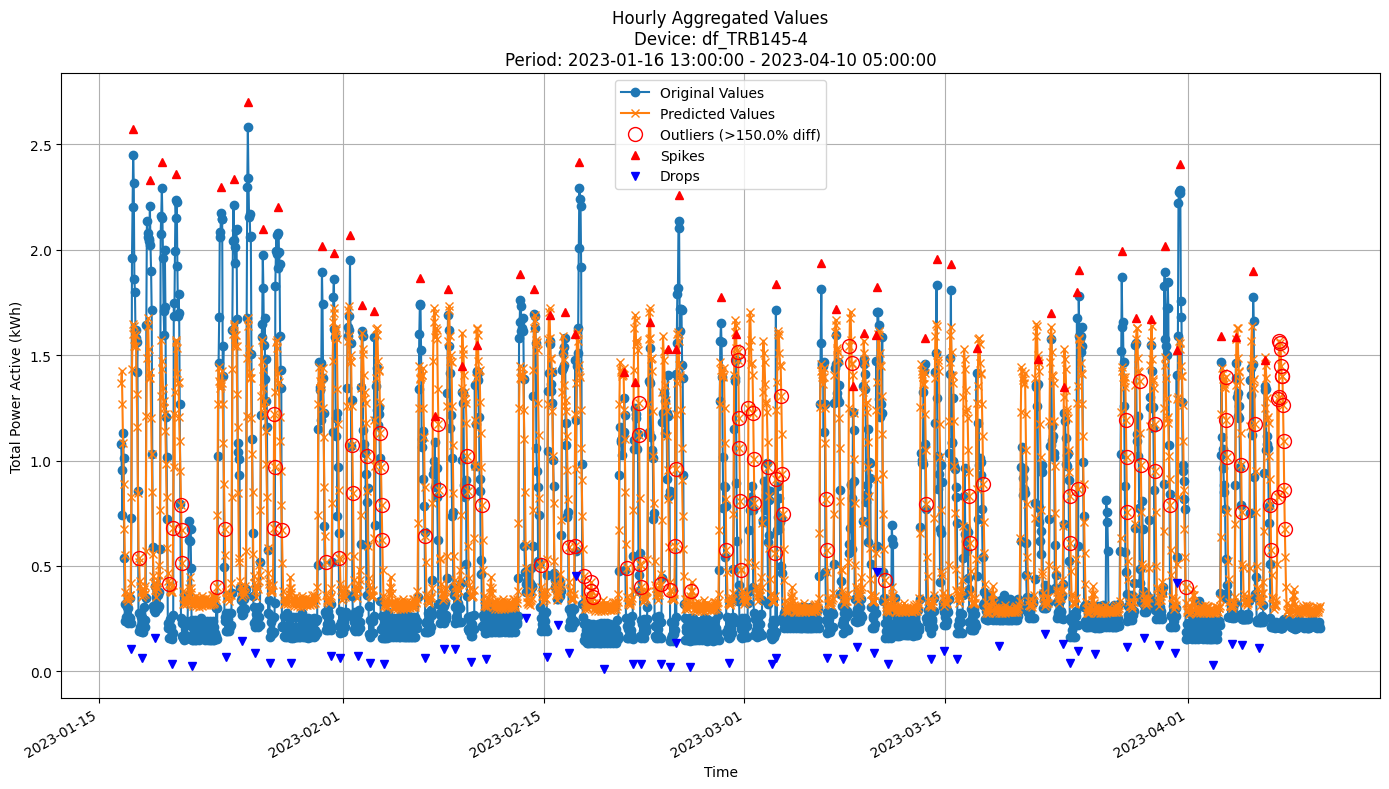


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.3034
MAE: 0.2180
MAPE: 58.1053%

Directional Metrics:
Directional Accuracy: 59.3423%
First-Diff Correlation: 0.6333

Immediate Detection (delta=0):
Spikes:
  Precision: 0.2203
  Recall: 0.2203
  F1 Score: 0.2203
Drops:
  Precision: 0.1017
  Recall: 0.1017
  F1 Score: 0.1017

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.5593
  Recall: 0.5593
  F1 Score: 0.5593
Drops:
  Precision: 0.1864
  Recall: 0.1864
  F1 Score: 0.1864


In [10]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in bl_mean_valid_period_predictions.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, bl_mean_valid_period_predictions[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, bl_mean_valid_period_predictions[device_id][i]['y_pred']], axis=0)
    
    plot_hourly_predictions(y_valid,
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id,
                            outlier_threshold=1.5,
                            )

### Baseline model (predict previous value)

In [11]:
update_freq = "1h"
bl_prev = PreviousValueRegressor
bl_prev_params = {'is_residual': USE_RESIDUAL}

In [ ]:
bl_prev_train_period_predictions, bl_prev_valid_period_predictions,\
bl_prev_train_period_metrics, bl_prev_valid_period_metrics = all_valid_splits_seq_fit_predict(
    model_class=bl_prev,
    model_params=bl_prev_params,
    train=train,
    valid=valid,
    use_residuals=USE_RESIDUAL,
    incremental=True,
    data_freq=DATA_FREQUENCY,
    forecast_horizon=FORECAST_HORIZON,
    features=ALL_FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE,
    start_split=0,
    verbose=1
)

Processing splits:   0%|          | 0/6 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 79
Filtered feature count: 79
Excluded lag features: None
Valid features: ['hour', 'weekday', 'month', 'L1_act_power_lag_1h', 'L1_act_power_lag_24h', 'L1_act_power_lag_1455min', 'L1_act_power_lag_168h', 'L1_app_power_lag_1h', 'L1_app_power_lag_24h', 'L1_app_power_lag_1455min', 'L1_app_power_lag_168h', 'L1_current_lag_1h', 'L1_current_lag_24h', 'L1_current_lag_1455min', 'L1_current_lag_168h', 'L1_react_power_lag_1h', 'L1_react_power_lag_24h', 'L1_react_power_lag_1455min', 'L1_react_power_lag_168h', 'L1_voltage_lag_1h', 'L1_voltage_lag_24h', 'L1_voltage_lag_1455min', 'L1_voltage_lag_168h', 'L2_act_power_lag_1h', 'L2_act_power_lag_24h', 'L2_act_power_lag_1455min', 'L2_act_power_lag_168h', 'L2_app_power_lag_1h', 'L2_app_power_lag_24h', 'L2_app_power_lag_1455min', 'L2_app_power_lag_168h', 'L2_current_lag_1h', 'L2_current_lag_24h', 'L2_current_lag_1455min', 'L2_current_lag_168h', 'L2_react_power_lag_1h', 'L2_react_power_lag_2

Processing devices in split 1:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 79
Filtered feature count: 79
Excluded lag features: None
Valid features: ['hour', 'weekday', 'month', 'L1_act_power_lag_1h', 'L1_act_power_lag_24h', 'L1_act_power_lag_1455min', 'L1_act_power_lag_168h', 'L1_app_power_lag_1h', 'L1_app_power_lag_24h', 'L1_app_power_lag_1455min', 'L1_app_power_lag_168h', 'L1_current_lag_1h', 'L1_current_lag_24h', 'L1_current_lag_1455min', 'L1_current_lag_168h', 'L1_react_power_lag_1h', 'L1_react_power_lag_24h', 'L1_react_power_lag_1455min', 'L1_react_power_lag_168h', 'L1_voltage_lag_1h', 'L1_voltage_lag_24h', 'L1_voltage_lag_1455min', 'L1_voltage_lag_168h', 'L2_act_power_lag_1h', 'L2_act_power_lag_24h', 'L2_act_power_lag_1455min', 'L2_act_power_lag_168h', 'L2_app_power_lag_1h', 'L2_app_power_lag_24h', 'L2_app_power_lag_1455min', 'L2_app_power_lag_168h', 'L2_current_lag_1h', 'L2_current_lag_24h', 'L2_current_lag_1455min', 'L2_current_lag_168h', 'L2_react_power_lag_1h', 'L2_react_power_lag_2

Processing devices in split 2:   0%|          | 0/1 [00:00<?, ?it/s]

... (3 outputs left out)

Processing devices in split 4:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 79
Filtered feature count: 79
Excluded lag features: None
Valid features: ['hour', 'weekday', 'month', 'L1_act_power_lag_1h', 'L1_act_power_lag_24h', 'L1_act_power_lag_1455min', 'L1_act_power_lag_168h', 'L1_app_power_lag_1h', 'L1_app_power_lag_24h', 'L1_app_power_lag_1455min', 'L1_app_power_lag_168h', 'L1_current_lag_1h', 'L1_current_lag_24h', 'L1_current_lag_1455min', 'L1_current_lag_168h', 'L1_react_power_lag_1h', 'L1_react_power_lag_24h', 'L1_react_power_lag_1455min', 'L1_react_power_lag_168h', 'L1_voltage_lag_1h', 'L1_voltage_lag_24h', 'L1_voltage_lag_1455min', 'L1_voltage_lag_168h', 'L2_act_power_lag_1h', 'L2_act_power_lag_24h', 'L2_act_power_lag_1455min', 'L2_act_power_lag_168h', 'L2_app_power_lag_1h', 'L2_app_power_lag_24h', 'L2_app_power_lag_1455min', 'L2_app_power_lag_168h', 'L2_current_lag_1h', 'L2_current_lag_24h', 'L2_current_lag_1455min', 'L2_current_lag_168h', 'L2_react_power_lag_1h', 'L2_react_power_lag_2

Processing devices in split 5:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 79
Filtered feature count: 79
Excluded lag features: None
Valid features: ['hour', 'weekday', 'month', 'L1_act_power_lag_1h', 'L1_act_power_lag_24h', 'L1_act_power_lag_1455min', 'L1_act_power_lag_168h', 'L1_app_power_lag_1h', 'L1_app_power_lag_24h', 'L1_app_power_lag_1455min', 'L1_app_power_lag_168h', 'L1_current_lag_1h', 'L1_current_lag_24h', 'L1_current_lag_1455min', 'L1_current_lag_168h', 'L1_react_power_lag_1h', 'L1_react_power_lag_24h', 'L1_react_power_lag_1455min', 'L1_react_power_lag_168h', 'L1_voltage_lag_1h', 'L1_voltage_lag_24h', 'L1_voltage_lag_1455min', 'L1_voltage_lag_168h', 'L2_act_power_lag_1h', 'L2_act_power_lag_24h', 'L2_act_power_lag_1455min', 'L2_act_power_lag_168h', 'L2_app_power_lag_1h', 'L2_app_power_lag_24h', 'L2_app_power_lag_1455min', 'L2_app_power_lag_168h', 'L2_current_lag_1h', 'L2_current_lag_24h', 'L2_current_lag_1455min', 'L2_current_lag_168h', 'L2_react_power_lag_1h', 'L2_react_power_lag_2

#### Results

In [13]:
print("\n\nValid period metrics:")
bl_prev_all_time_valid_metrics = all_time_aggregation_metrics(bl_prev_valid_period_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Valid period metrics:


Aggregated Metrics Across Periods
Device ID: df_TRB145-4
--------------------------------------------------
15min Metrics:
	RMSE: 0.2101 ± 0.0204
	MAE: 0.1068 ± 0.0114
	MAPE: 21.5092% ± 5.0289%

	Directional Metrics:
		Directional Accuracy: 11.9993% ± 0.8914%
		First-Diff Correlation: 0.0528 ± 0.0328

	Immediate Detection (delta=0):
		Spike Precision: 0.0828 ± 0.0606
		Spike Recall: 0.0670 ± 0.0485
		Spike F1: 0.0738 ± 0.0533
		Drop Precision: 0.0783 ± 0.0641
		Drop Recall: 0.0689 ± 0.0663
		Drop F1: 0.0729 ± 0.0653

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.2767 ± 0.1163
		Spike Recall: 0.2294 ± 0.0665
		Spike F1: 0.2496 ± 0.0865
		Drop Precision: 0.1826 ± 0.0526
		Drop Recall: 0.1558 ± 0.0482
		Drop F1: 0.1674 ± 0.0495
Hourly Metrics:
	RMSE: 0.1828 ± 0.0188
	MAE: 0.1013 ± 0.0108
	MAPE: 19.7203% ± 4.4735%

	Directional Metrics:
		Directional Accuracy: 58.5057% ± 4.1851%
		First-Diff Correlation: 0.4544 ± 0.0551

	Immediate Detection (delta=0):

#### Validation plots

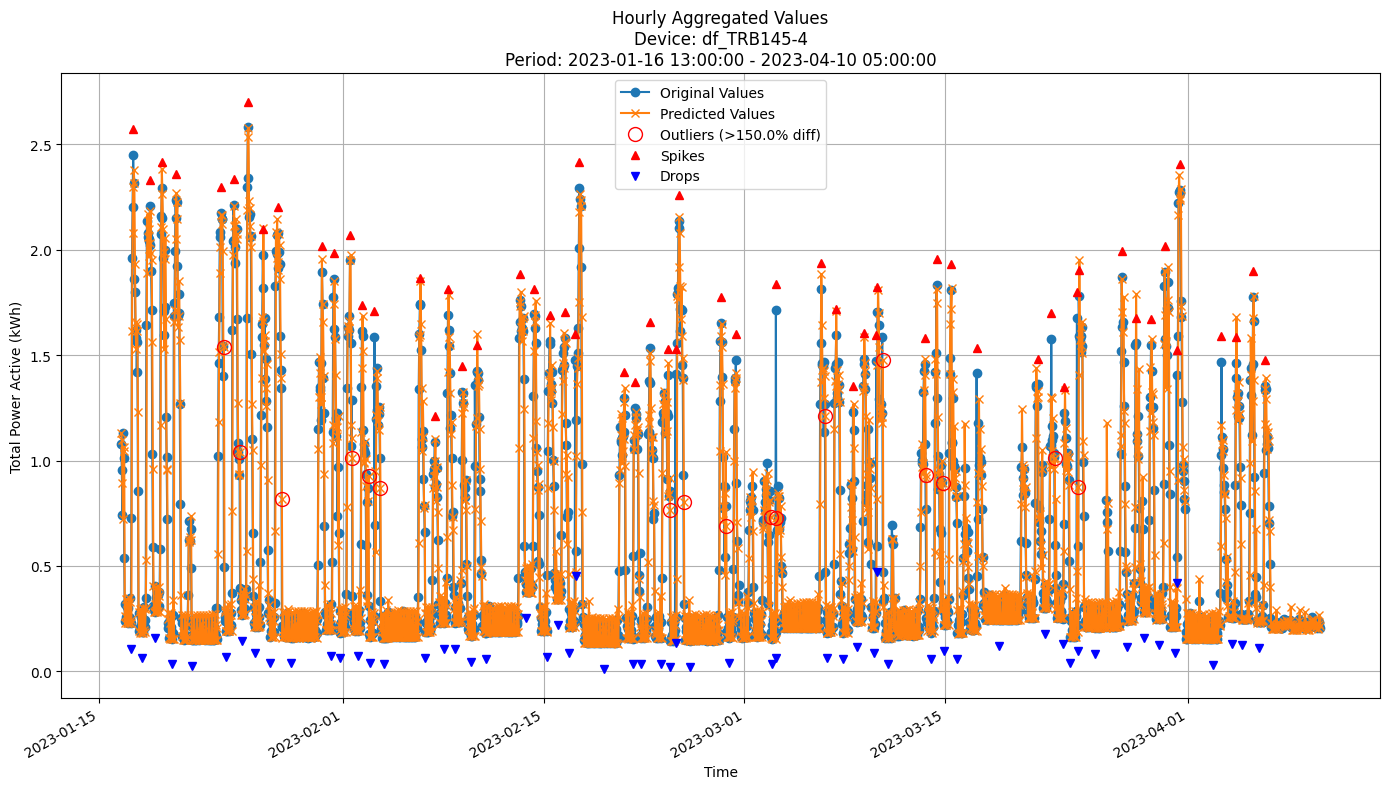


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.1870
MAE: 0.1044
MAPE: 23.3244%

Directional Metrics:
Directional Accuracy: 56.6517%
First-Diff Correlation: 0.4319

Immediate Detection (delta=0):
Spikes:
  Precision: 0.2222
  Recall: 0.1695
  F1 Score: 0.1923
Drops:
  Precision: 0.0682
  Recall: 0.0508
  F1 Score: 0.0583

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.8000
  Recall: 0.6102
  F1 Score: 0.6923
Drops:
  Precision: 0.4545
  Recall: 0.3390
  F1 Score: 0.3883


In [14]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in bl_prev_valid_period_predictions.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, bl_prev_valid_period_predictions[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, bl_prev_valid_period_predictions[device_id][i]['y_pred']], axis=0)
    
    plot_hourly_predictions(y_valid,
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id,
                            outlier_threshold=1.5,
                            )

### GBDT

In [15]:
update_freq = "14D"  # Update the model every 14 days

gbdt = GradientBoostingRegressor
gbdt_params = dict(n_estimators=100, learning_rate=0.03, subsample=0.8, max_depth=10, random_state=42)


# Results from hyperparam. tuning
# RMSE (best: 0.230)
#     Parameters: {'n_estimators': 50, 'learning_rate': 0.1, 'max_depth': 3, 'subsample': 0.8, 'random_state': 42}
# MAE (best: 0.143)
#     Parameters: {'n_estimators': 100, 'learning_rate': 0.05, 'max_depth': 3, 'subsample': 1.0, 'random_state': 42}
# MAPE (best: 28.070%)
#     Parameters: {'n_estimators': 100, 'learning_rate': 0.05, 'max_depth': 3, 'subsample': 1.0, 'random_state': 42}
# DIR_ACCURACY (best: 62.673%)
#     Parameters: {'n_estimators': 50, 'learning_rate': 0.1, 'max_depth': 12, 'subsample': 0.8, 'random_state': 42}
# FIRST_DIFF_CORR (best: 42.984%)
#     Parameters: {'n_estimators': 50, 'learning_rate': 0.05, 'max_depth': 3, 'subsample': 0.6, 'random_state': 42}
# SPIKES_F1 (best: 20.873%)
#     Parameters: {'n_estimators': 50, 'learning_rate': 0.1, 'max_depth': 3, 'subsample': 0.6, 'random_state': 42}
# DROPS_F1 (best: 15.373%)
#     Parameters: {'n_estimators': 50, 'learning_rate': 0.15, 'max_depth': 15, 'subsample': 0.8, 'random_state': 42}

In [ ]:
gbdt_train_period_predictions, gbdt_valid_period_predictions, \
gbdt_train_period_metrics, gbdt_valid_period_metrics = all_valid_splits_seq_fit_predict(
    model_class=gbdt, 
    model_params=gbdt_params, 
    train=train, 
    valid=valid,
    use_residuals=USE_RESIDUAL,
    incremental=False,
    data_freq=DATA_FREQUENCY, 
    forecast_horizon=FORECAST_HORIZON,
    features=ALL_FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE,
    start_split=0, 
    #end_split=4,  # Use only the third and fourth splits
    verbose=True
)

Processing splits:   0%|          | 0/6 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2022-09-26 14:15:00+02:00 to 2022-10-24 13:45:00+02:00

Time: 11.49 seconds
Predicting for chunk from 2022-10-24 14:00:00+02:00 to 2022-11-07 13:00:00+01:00

-------------------------

Retraining model on data from 2022-09-26 14:15:00+02:00 to 2022-11-07 13:00:00+01:00

Time: 17.53 seconds
Predicting for chunk from 2022-11-07 13:15:00+01:00 to 2022-11-21 12:45:00+01:00

-------------------------
Model's memory usage: 0.010811 MB
Metrics for Device: df_TRB145-4 | Period: 2022-10-24 14:00:00+02:00 - 2022-11-21 12:45:00+01:00
15min Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.3206
	MAE: 0.1921
	MAPE: 21.8908%

Directional Metrics:
	Directional Accuracy: 55.0800%
	First-Diff Correlation: 0.0571

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection del

Processing devices in split 1:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2022-09-26 14:15:00+02:00 to 2022-11-21 12:45:00+01:00

Time: 23.90 seconds
Predicting for chunk from 2022-11-21 13:00:00+01:00 to 2022-12-05 13:00:00+01:00

-------------------------

Retraining model on data from 2022-09-26 14:15:00+02:00 to 2022-12-05 13:00:00+01:00

Time: 30.66 seconds
Predicting for chunk from 2022-12-05 13:15:00+01:00 to 2022-12-19 12:45:00+01:00

-------------------------
Model's memory usage: 0.010735 MB
Metrics for Device: df_TRB145-4 | Period: 2022-11-21 13:00:00+01:00 - 2022-12-19 12:45:00+01:00
15min Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.4270
	MAE: 0.2760
	MAPE: 87.9566%

Directional Metrics:
	Directional Accuracy: 53.5169%
	First-Diff Correlation: 0.0825

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection del

Processing devices in split 2:   0%|          | 0/1 [00:00<?, ?it/s]

... (3 outputs left out)

Processing devices in split 4:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2022-09-26 14:15:00+02:00 to 2023-02-13 12:45:00+01:00

Time: 63.56 seconds
Predicting for chunk from 2023-02-13 13:00:00+01:00 to 2023-02-27 13:00:00+01:00

-------------------------

Retraining model on data from 2022-09-26 14:15:00+02:00 to 2023-02-27 13:00:00+01:00

Time: 70.47 seconds
Predicting for chunk from 2023-02-27 13:15:00+01:00 to 2023-03-13 12:45:00+01:00

-------------------------
Model's memory usage: 0.010506 MB
Metrics for Device: df_TRB145-4 | Period: 2023-02-13 13:00:00+01:00 - 2023-03-13 12:45:00+01:00
15min Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2330
	MAE: 0.1600
	MAPE: 48.1873%

Directional Metrics:
	Directional Accuracy: 53.7402%
	First-Diff Correlation: 0.1806

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0526
		Recall: 0.0500
		F1: 0.0513
	Drops:
		Precision: 0.0500
		Recall: 0.0476
		F1: 0.0488

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection del

Processing devices in split 5:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2022-09-26 14:15:00+02:00 to 2023-03-13 12:45:00+01:00

Time: 78.05 seconds
Predicting for chunk from 2023-03-13 13:00:00+01:00 to 2023-03-27 14:00:00+02:00

-------------------------

Retraining model on data from 2022-09-26 14:15:00+02:00 to 2023-03-27 14:00:00+02:00

Time: 85.38 seconds
Predicting for chunk from 2023-03-27 14:15:00+02:00 to 2023-04-10 05:30:00+02:00

-------------------------
Model's memory usage: 0.010429 MB
Metrics for Device: df_TRB145-4 | Period: 2023-03-13 13:00:00+01:00 - 2023-04-10 05:30:00+02:00
15min Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2318
	MAE: 0.1453
	MAPE: 36.8457%

Directional Metrics:
	Directional Accuracy: 52.7882%
	First-Diff Correlation: 0.0936

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0435
		Recall: 0.0400
		F1: 0.0417
	Drops:
		Precision: 0.0400
		Recall: 0.0400
		F1: 0.0400

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection del

#### Results

In [17]:
print("\n\nTrain period metrics:")
gbdt_all_time_train_metrics = all_time_aggregation_metrics(gbdt_train_period_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\nValid period metrics:")
gbdt_all_time_valid_metrics = all_time_aggregation_metrics(gbdt_valid_period_metrics, data_freq=DATA_FREQUENCY, verbose=True)
# Hourly Metrics:
# 	RMSE: 0.2486 ± 0.0612
# 	MAE: 0.1594 ± 0.0516
# 	MAPE: 33.4958% ± 5.3587%

# 	Directional Metrics:
# 		Directional Accuracy: 62.4754% ± 7.1041%
# 		First-Diff Correlation: 0.3821 ± 0.0970

# 	Immediate Detection (delta=0):
# 		Spike Precision: 0.1544 ± 0.1193
# 		Spike Recall: 0.1617 ± 0.1297
# 		Spike F1: 0.1577 ± 0.1238
# 		Drop Precision: 0.1459 ± 0.0857
# 		Drop Recall: 0.1534 ± 0.0909
# 		Drop F1: 0.1493 ± 0.0879

# 	1-Hour Delayed Detection (delta=1):
# 		Spike Precision: 0.4691 ± 0.2714
# 		Spike Recall: 0.4908 ± 0.2907
# 		Spike F1: 0.4788 ± 0.2795
# 		Drop Precision: 0.2117 ± 0.1062
# 		Drop Recall: 0.2201 ± 0.1161
# 		Drop F1: 0.2153 ± 0.1100



Train period metrics:


Aggregated Metrics Across Periods
Device ID: df_TRB145-4
--------------------------------------------------
15min Metrics:
	RMSE: 0.0486 ± 0.0111
	MAE: 0.0367 ± 0.0079
	MAPE: 8.2914% ± 2.3209%

	Directional Metrics:
		Directional Accuracy: 75.2383% ± 3.0443%
		First-Diff Correlation: 0.9550 ± 0.0239

	Immediate Detection (delta=0):
		Spike Precision: 0.8513 ± 0.2107
		Spike Recall: 0.5880 ± 0.2601
		Spike F1: 0.6440 ± 0.2404
		Drop Precision: 0.0113 ± 0.0173
		Drop Recall: 0.0126 ± 0.0200
		Drop F1: 0.0119 ± 0.0185

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.9236 ± 0.1162
		Spike Recall: 0.6651 ± 0.2855
		Spike F1: 0.7185 ± 0.2437
		Drop Precision: 0.0362 ± 0.0512
		Drop Recall: 0.0394 ± 0.0558
		Drop F1: 0.0376 ± 0.0532
Hourly Metrics:
	RMSE: 0.0393 ± 0.0082
	MAE: 0.0296 ± 0.0056
	MAPE: 6.3870% ± 1.5552%

	Directional Metrics:
		Directional Accuracy: 91.9580% ± 2.0166%
		First-Diff Correlation: 0.9907 ± 0.0056

	Immediate Detection (delta=0):
	

#### Training plots

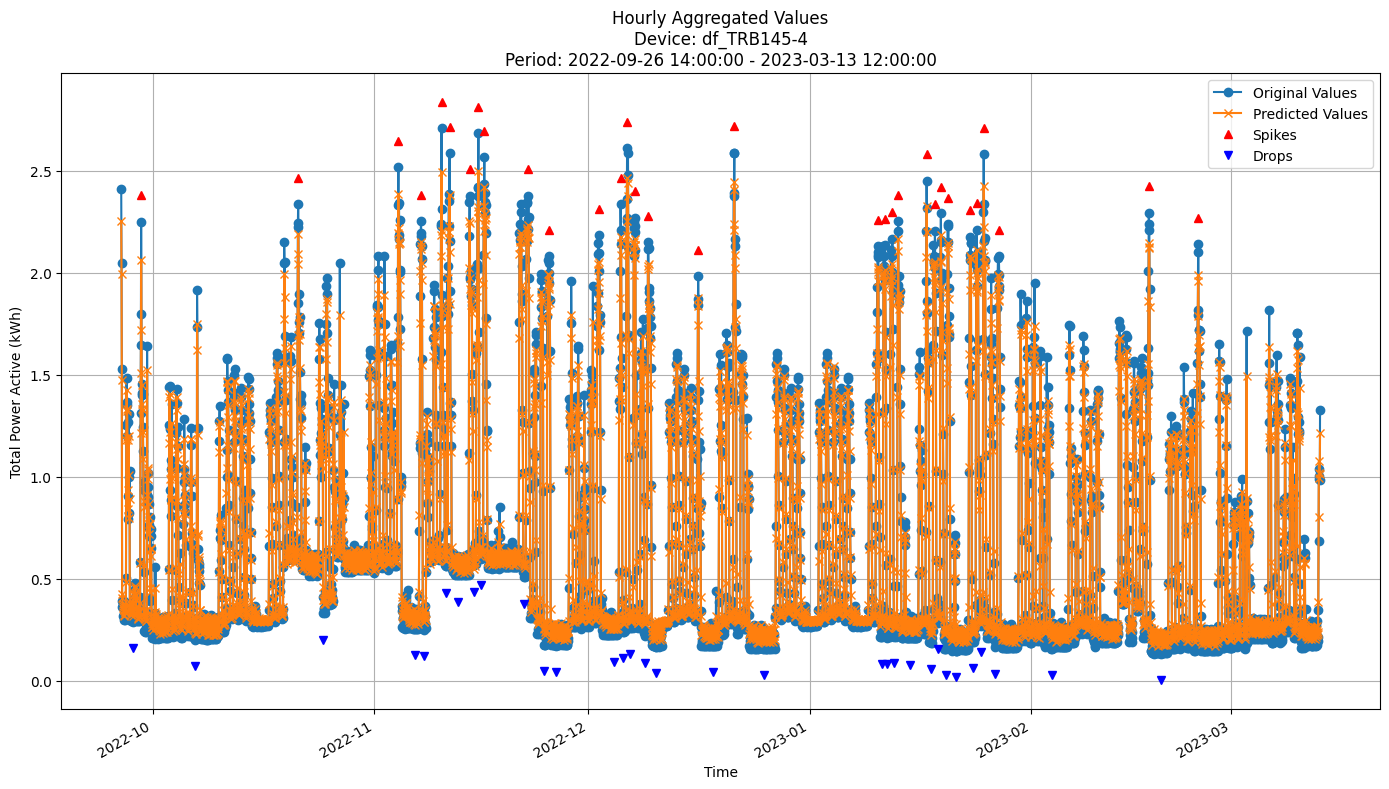


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0499
MAE: 0.0367
MAPE: 8.6261%

Directional Metrics:
Directional Accuracy: 89.6800%
First-Diff Correlation: 0.9822

Immediate Detection (delta=0):
Spikes:
  Precision: 0.7429
  Recall: 0.8125
  F1 Score: 0.7761
Drops:
  Precision: 0.2571
  Recall: 0.2812
  F1 Score: 0.2687

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.8000
  Recall: 0.8750
  F1 Score: 0.8358
Drops:
  Precision: 0.2571
  Recall: 0.2812
  F1 Score: 0.2687


In [18]:
for device_id in gbdt_train_period_predictions.keys():
    y_train = gbdt_train_period_predictions[device_id][-1]['y_true']
    y_pred_train = gbdt_train_period_predictions[device_id][-1]['y_pred']
    
    # Plot hourly predictions
    plot_hourly_predictions(y_train,
                            y_pred_train, 
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id,
                            outlier_threshold=1.5)
# 0.17, 0.12, 25.55, 70.81%, 0.72

#### Validation plots
Plot only the last few periods of predictions

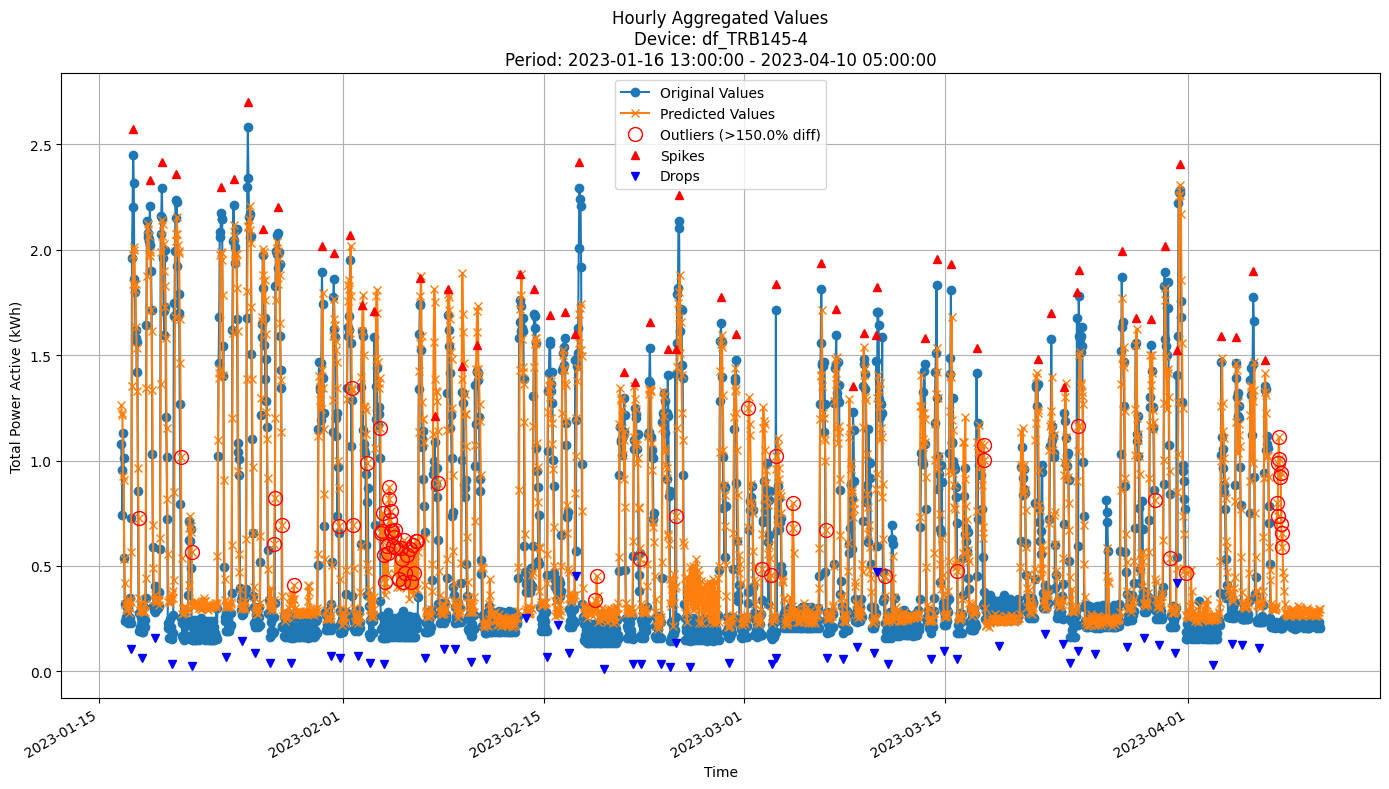


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.2161
MAE: 0.1476
MAPE: 40.6167%

Directional Metrics:
Directional Accuracy: 62.0329%
First-Diff Correlation: 0.4835

Immediate Detection (delta=0):
Spikes:
  Precision: 0.1111
  Recall: 0.1017
  F1 Score: 0.1062
Drops:
  Precision: 0.0741
  Recall: 0.0678
  F1 Score: 0.0708

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.5556
  Recall: 0.5085
  F1 Score: 0.5310
Drops:
  Precision: 0.1852
  Recall: 0.1695
  F1 Score: 0.1770


In [19]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in gbdt_valid_period_predictions.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, gbdt_valid_period_predictions[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, gbdt_valid_period_predictions[device_id][i]['y_pred']], axis=0)
    
    plot_hourly_predictions(y_valid, 
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id, 
                            outlier_threshold=1.5)

# Basic Prediction Metrics:
# RMSE: 0.2195
# MAE: 0.1398
# MAPE: 33.6987%

### Random Forest model

In [20]:
update_freq = "14D"  # Update the model every 14 days
rf = RandomForestRegressor
rf_params = dict(n_estimators=100, max_depth=10, max_features='sqrt', random_state=42, n_jobs=-1)

# Results from hyperparam. tuning
# BEST RMSE: 0.230
#    Best Parameters: {'n_estimators': 150, 'max_depth': 15, 'max_features': 0.5, 'random_state': 42, 'n_jobs': -1}
# BEST MAE: 0.140
#    Best Parameters: {'n_estimators': 50, 'max_depth': 7, 'max_features': 0.7, 'random_state': 42, 'n_jobs': -1}
# BEST MAPE: 27.282%
#    Best Parameters: {'n_estimators': 50, 'max_depth': 7, 'max_features': 0.7, 'random_state': 42, 'n_jobs': -1}
# BEST DIR_ACCURACY: 63.559%
#    Best Parameters: {'n_estimators': 200, 'max_depth': 20, 'max_features': 0.7, 'random_state': 42, 'n_jobs': -1}
# BEST FIRST_DIFF_CORR: 44.507%
#    Best Parameters: {'n_estimators': 300, 'max_depth': 5, 'max_features': 0.3, 'random_state': 42, 'n_jobs': -1}
# BEST SPIKES_F1: 20.414%
#    Best Parameters: {'n_estimators': 50, 'max_depth': 5, 'max_features': 0.7, 'random_state': 42, 'n_jobs': -1}
# BEST DROPS_F1: 14.260%
#    Best Parameters: {'n_estimators': 200, 'max_depth': 20, 'max_features': 0.3, 'random_state': 42, 'n_jobs': -1}

In [ ]:

rf_train_period_predictions, rf_valid_period_predictions, \
rf_train_period_metrics, rf_valid_period_metrics = all_valid_splits_seq_fit_predict(
    model_class=rf, 
    model_params=rf_params, 
    train=train, 
    valid=valid, 
    use_residuals=USE_RESIDUAL,
    incremental=False,
    data_freq=DATA_FREQUENCY, 
    forecast_horizon=FORECAST_HORIZON,
    features=ALL_FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE,
    start_split=0, 
    #end_split=4,  # Use only the third and fourth splits
    verbose=True
)

Processing splits:   0%|          | 0/6 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2022-09-26 14:15:00+02:00 to 2022-10-24 13:45:00+02:00

Time: 0.21 seconds
Predicting for chunk from 2022-10-24 14:00:00+02:00 to 2022-11-07 13:00:00+01:00

-------------------------

Retraining model on data from 2022-09-26 14:15:00+02:00 to 2022-11-07 13:00:00+01:00

Time: 0.23 seconds
Predicting for chunk from 2022-11-07 13:15:00+01:00 to 2022-11-21 12:45:00+01:00

-------------------------
Model's memory usage: 0.042160 MB
Metrics for Device: df_TRB145-4 | Period: 2022-10-24 14:00:00+02:00 - 2022-11-21 12:45:00+01:00
15min Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.3064
	MAE: 0.1857
	MAPE: 20.8510%

Directional Metrics:
	Directional Accuracy: 54.7079%
	First-Diff Correlation: 0.0892

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.1000
		Recall: 0.0556
		F1: 0.0714
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay

Processing devices in split 1:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2022-09-26 14:15:00+02:00 to 2022-11-21 12:45:00+01:00

Time: 0.33 seconds
Predicting for chunk from 2022-11-21 13:00:00+01:00 to 2022-12-05 13:00:00+01:00

-------------------------

Retraining model on data from 2022-09-26 14:15:00+02:00 to 2022-12-05 13:00:00+01:00

Time: 0.38 seconds
Predicting for chunk from 2022-12-05 13:15:00+01:00 to 2022-12-19 12:45:00+01:00

-------------------------
Model's memory usage: 0.042152 MB
Metrics for Device: df_TRB145-4 | Period: 2022-11-21 13:00:00+01:00 - 2022-12-19 12:45:00+01:00
15min Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2777
	MAE: 0.1848
	MAPE: 45.5878%

Directional Metrics:
	Directional Accuracy: 56.9408%
	First-Diff Correlation: 0.1143

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay

Processing devices in split 2:   0%|          | 0/1 [00:00<?, ?it/s]

... (3 outputs left out)

Processing devices in split 4:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2022-09-26 14:15:00+02:00 to 2023-02-13 12:45:00+01:00

Time: 0.72 seconds
Predicting for chunk from 2023-02-13 13:00:00+01:00 to 2023-02-27 13:00:00+01:00

-------------------------

Retraining model on data from 2022-09-26 14:15:00+02:00 to 2023-02-27 13:00:00+01:00

Time: 0.80 seconds
Predicting for chunk from 2023-02-27 13:15:00+01:00 to 2023-03-13 12:45:00+01:00

-------------------------
Model's memory usage: 0.042152 MB
Metrics for Device: df_TRB145-4 | Period: 2023-02-13 13:00:00+01:00 - 2023-03-13 12:45:00+01:00
15min Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2366
	MAE: 0.1556
	MAPE: 42.9380%

Directional Metrics:
	Directional Accuracy: 51.9539%
	First-Diff Correlation: 0.2288

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0526
		Recall: 0.0500
		F1: 0.0513
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay

Processing devices in split 5:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2022-09-26 14:15:00+02:00 to 2023-03-13 12:45:00+01:00

Time: 0.93 seconds
Predicting for chunk from 2023-03-13 13:00:00+01:00 to 2023-03-27 14:00:00+02:00

-------------------------

Retraining model on data from 2022-09-26 14:15:00+02:00 to 2023-03-27 14:00:00+02:00

Time: 0.99 seconds
Predicting for chunk from 2023-03-27 14:15:00+02:00 to 2023-04-10 05:30:00+02:00

-------------------------
Model's memory usage: 0.042152 MB
Metrics for Device: df_TRB145-4 | Period: 2023-03-13 13:00:00+01:00 - 2023-04-10 05:30:00+02:00
15min Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2297
	MAE: 0.1480
	MAPE: 35.6761%

Directional Metrics:
	Directional Accuracy: 51.9593%
	First-Diff Correlation: 0.1444

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.1000
		Recall: 0.0800
		F1: 0.0889
	Drops:
		Precision: 0.0500
		Recall: 0.0400
		F1: 0.0444

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay

#### Results

In [22]:
print("\n\nTrain period metrics:")
rf_all_time_train_metrics = all_time_aggregation_metrics(rf_train_period_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\nValid period metrics:")
rf_all_time_valid_metrics = all_time_aggregation_metrics(rf_train_period_metrics, data_freq=DATA_FREQUENCY, verbose=True)

# Best values:
# Hourly Metrics:
# 	RMSE: 0.2221 ± 0.0148
# 	MAE: 0.1267 ± 0.0092
# 	MAPE: 22.1472% ± 2.0063%

# 	Directional Metrics:
# 		Directional Accuracy: 60.8511% ± 2.9815%
# 		First-Diff Correlation: 0.4859 ± 0.0565

# 	Immediate Detection (delta=0):
# 		Spike Precision: 0.2094 ± 0.0638
# 		Spike Recall: 0.1844 ± 0.0780
# 		Spike F1: 0.1927 ± 0.0741
# 		Drop Precision: 0.0547 ± 0.0125
# 		Drop Recall: 0.1408 ± 0.0536
# 		Drop F1: 0.0779 ± 0.0216

# 	1-Hour Delayed Detection (delta=1):
# 		Spike Precision: 0.4647 ± 0.0473
# 		Spike Recall: 0.3984 ± 0.1023
# 		Spike F1: 0.4191 ± 0.0799
# 		Drop Precision: 0.1104 ± 0.0172
# 		Drop Recall: 0.2821 ± 0.0884
# 		Drop F1: 0.1571 ± 0.0324



Train period metrics:


Aggregated Metrics Across Periods
Device ID: df_TRB145-4
--------------------------------------------------
15min Metrics:
	RMSE: 0.1059 ± 0.0195
	MAE: 0.0652 ± 0.0129
	MAPE: 12.1099% ± 3.2044%

	Directional Metrics:
		Directional Accuracy: 68.3421% ± 1.6986%
		First-Diff Correlation: 0.7811 ± 0.0678

	Immediate Detection (delta=0):
		Spike Precision: 0.1857 ± 0.1868
		Spike Recall: 0.1298 ± 0.1374
		Spike F1: 0.1505 ± 0.1545
		Drop Precision: 0.0153 ± 0.0217
		Drop Recall: 0.0097 ± 0.0142
		Drop F1: 0.0117 ± 0.0167

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.3571 ± 0.3684
		Spike Recall: 0.2455 ± 0.2612
		Spike F1: 0.2863 ± 0.2968
		Drop Precision: 0.0487 ± 0.0707
		Drop Recall: 0.0374 ± 0.0594
		Drop F1: 0.0420 ± 0.0645
Hourly Metrics:
	RMSE: 0.0854 ± 0.0183
	MAE: 0.0520 ± 0.0112
	MAPE: 9.0629% ± 2.4341%

	Directional Metrics:
		Directional Accuracy: 82.9841% ± 3.0300%
		First-Diff Correlation: 0.9007 ± 0.0364

	Immediate Detection (delta=0):


#### Training plots
Plot only the last period of predictions

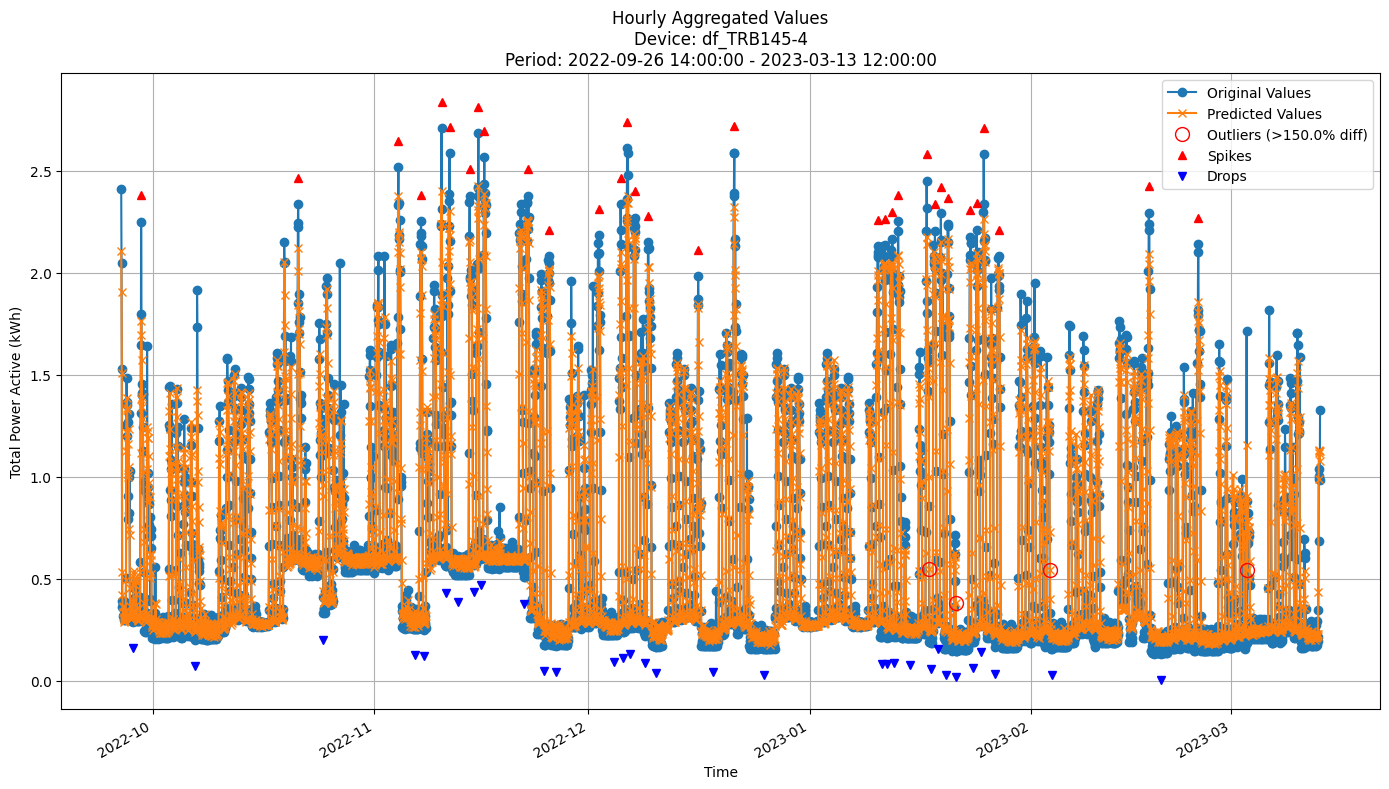


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.1064
MAE: 0.0653
MAPE: 12.6597%

Directional Metrics:
Directional Accuracy: 80.0050%
First-Diff Correlation: 0.8561

Immediate Detection (delta=0):
Spikes:
  Precision: 0.5909
  Recall: 0.4062
  F1 Score: 0.4815
Drops:
  Precision: 0.1364
  Recall: 0.0938
  F1 Score: 0.1111

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.7273
  Recall: 0.5000
  F1 Score: 0.5926
Drops:
  Precision: 0.1364
  Recall: 0.0938
  F1 Score: 0.1111


In [23]:
for device_id in rf_train_period_predictions.keys():
    y_train = rf_train_period_predictions[device_id][-1]['y_true']
    y_pred_train = rf_train_period_predictions[device_id][-1]['y_pred']
    plot_hourly_predictions(y_train, 
                            y_pred_train,
                            data_freq=DATA_FREQUENCY, 
                            device_id=device_id, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last periods of predictions

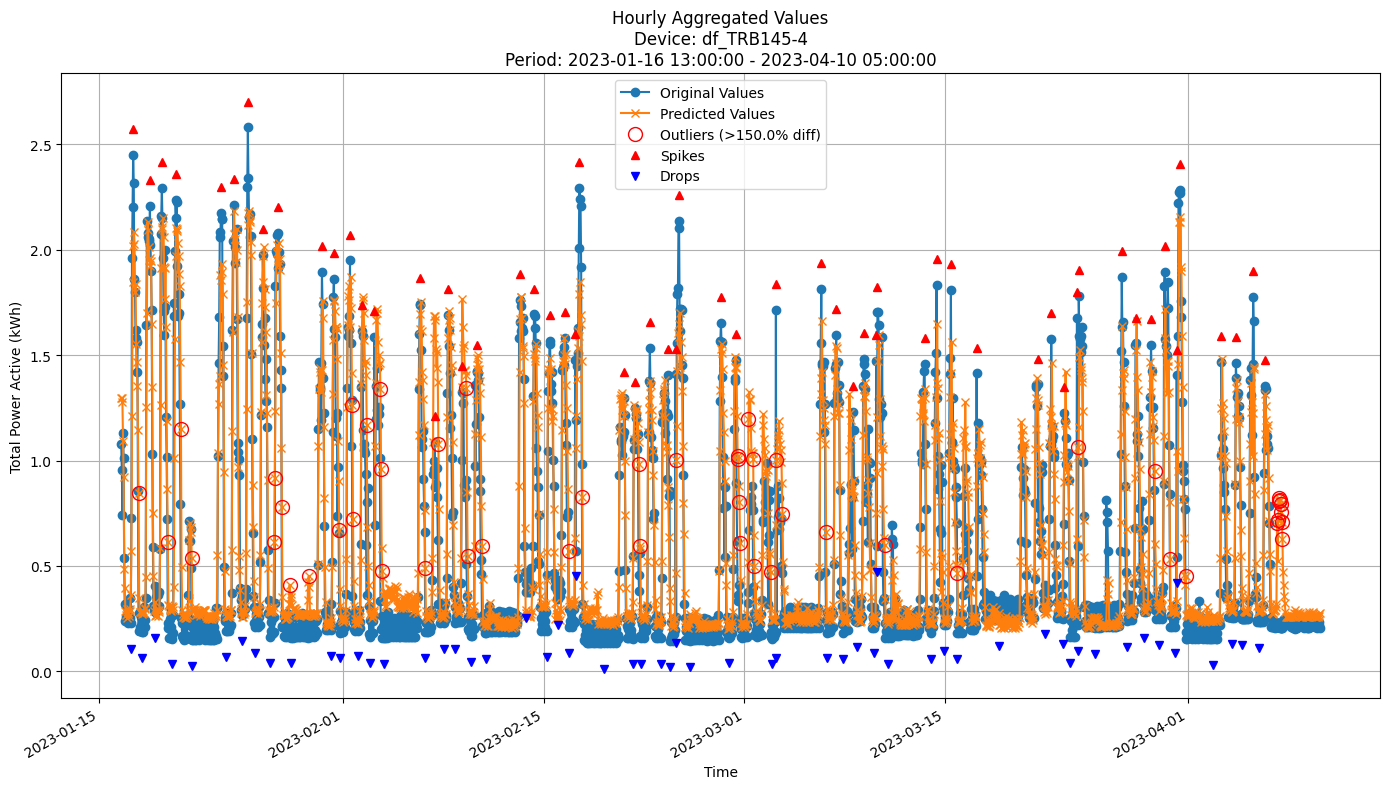


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.2222
MAE: 0.1442
MAPE: 35.3859%

Directional Metrics:
Directional Accuracy: 57.0005%
First-Diff Correlation: 0.4509

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0517
  Recall: 0.0508
  F1 Score: 0.0513
Drops:
  Precision: 0.0690
  Recall: 0.0678
  F1 Score: 0.0684

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.5690
  Recall: 0.5593
  F1 Score: 0.5641
Drops:
  Precision: 0.2069
  Recall: 0.2034
  F1 Score: 0.2051


In [24]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in rf_valid_period_predictions.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, rf_valid_period_predictions[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, rf_valid_period_predictions[device_id][i]['y_pred']], axis=0)
    
    plot_hourly_predictions(y_valid, 
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY, 
                            device_id=device_id, 
                            outlier_threshold=1.5)

### Hoeffding Tree

In [25]:
update_freq = "15min"  # for incremental models put the same as the data frequency to recreate real world scenario

hoef = HoeffdingTreeRegressor
hoef_params = dict(max_depth=10, grace_period=10, delta=0.5, tau=0.05, leaf_prediction="mean")


# Results from hyperparam. tuning
# BEST RMSE: 0.258
#    Best Parameters: {'max_depth': 10, 'grace_period': 48, 'tau': 0.1, 'delta': 0.1}
# BEST MAE: 0.162
#    Best Parameters: {'max_depth': 15, 'grace_period': 48, 'tau': 0.1, 'delta': 0.1}
# BEST MAPE: 30.209%
#    Best Parameters: {'max_depth': 15, 'grace_period': 48, 'tau': 0.1, 'delta': 0.1}
# BEST DIR_ACCURACY: 54.170%
#    Best Parameters: {'max_depth': 5, 'grace_period': 0, 'tau': 0.1, 'delta': 0.005}
# BEST FIRST_DIFF_CORR: 41.677%
#    Best Parameters: {'max_depth': 3, 'grace_period': 0, 'tau': 0.1, 'delta': 0.05}
# BEST SPIKES_F1: 18.787%
#    Best Parameters: {'max_depth': 3, 'grace_period': 24, 'tau': 0.001, 'delta': 0.05}
# BEST DROPS_F1: 10.620%
#    Best Parameters: {'max_depth': 10, 'grace_period': 24, 'tau': 0.1, 'delta': 0.005}


In [ ]:

hoef_all_train_preds, hoef_all_valid_preds, \
hoef_all_train_metrics, hoef_all_valid_metrics = all_valid_splits_seq_fit_predict(
    model_class=hoef, 
    model_params=hoef_params, 
    train=train, 
    valid=valid, 
    use_residuals=USE_RESIDUAL,
    incremental=True,
    data_freq=DATA_FREQUENCY,
    forecast_horizon=FORECAST_HORIZON,
    features=ALL_FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE, 
    start_split=0, 
    #end_split=4,  # Use only the third and fourth splits
    verbose=True
)

Processing splits:   0%|          | 0/6 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 79
Filtered feature count: 79
Excluded lag features: None
Valid features: ['hour', 'weekday', 'month', 'L1_act_power_lag_1h', 'L1_act_power_lag_24h', 'L1_act_power_lag_1455min', 'L1_act_power_lag_168h', 'L1_app_power_lag_1h', 'L1_app_power_lag_24h', 'L1_app_power_lag_1455min', 'L1_app_power_lag_168h', 'L1_current_lag_1h', 'L1_current_lag_24h', 'L1_current_lag_1455min', 'L1_current_lag_168h', 'L1_react_power_lag_1h', 'L1_react_power_lag_24h', 'L1_react_power_lag_1455min', 'L1_react_power_lag_168h', 'L1_voltage_lag_1h', 'L1_voltage_lag_24h', 'L1_voltage_lag_1455min', 'L1_voltage_lag_168h', 'L2_act_power_lag_1h', 'L2_act_power_lag_24h', 'L2_act_power_lag_1455min', 'L2_act_power_lag_168h', 'L2_app_power_lag_1h', 'L2_app_power_lag_24h', 'L2_app_power_lag_1455min', 'L2_app_power_lag_168h', 'L2_current_lag_1h', 'L2_current_lag_24h', 'L2_current_lag_1455min', 'L2_current_lag_168h', 'L2_react_power_lag_1h', 'L2_react_power_lag_2

Processing devices in split 1:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 79
Filtered feature count: 79
Excluded lag features: None
Valid features: ['hour', 'weekday', 'month', 'L1_act_power_lag_1h', 'L1_act_power_lag_24h', 'L1_act_power_lag_1455min', 'L1_act_power_lag_168h', 'L1_app_power_lag_1h', 'L1_app_power_lag_24h', 'L1_app_power_lag_1455min', 'L1_app_power_lag_168h', 'L1_current_lag_1h', 'L1_current_lag_24h', 'L1_current_lag_1455min', 'L1_current_lag_168h', 'L1_react_power_lag_1h', 'L1_react_power_lag_24h', 'L1_react_power_lag_1455min', 'L1_react_power_lag_168h', 'L1_voltage_lag_1h', 'L1_voltage_lag_24h', 'L1_voltage_lag_1455min', 'L1_voltage_lag_168h', 'L2_act_power_lag_1h', 'L2_act_power_lag_24h', 'L2_act_power_lag_1455min', 'L2_act_power_lag_168h', 'L2_app_power_lag_1h', 'L2_app_power_lag_24h', 'L2_app_power_lag_1455min', 'L2_app_power_lag_168h', 'L2_current_lag_1h', 'L2_current_lag_24h', 'L2_current_lag_1455min', 'L2_current_lag_168h', 'L2_react_power_lag_1h', 'L2_react_power_lag_2

Processing devices in split 2:   0%|          | 0/1 [00:00<?, ?it/s]

... (3 outputs left out)

Processing devices in split 4:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 79
Filtered feature count: 79
Excluded lag features: None
Valid features: ['hour', 'weekday', 'month', 'L1_act_power_lag_1h', 'L1_act_power_lag_24h', 'L1_act_power_lag_1455min', 'L1_act_power_lag_168h', 'L1_app_power_lag_1h', 'L1_app_power_lag_24h', 'L1_app_power_lag_1455min', 'L1_app_power_lag_168h', 'L1_current_lag_1h', 'L1_current_lag_24h', 'L1_current_lag_1455min', 'L1_current_lag_168h', 'L1_react_power_lag_1h', 'L1_react_power_lag_24h', 'L1_react_power_lag_1455min', 'L1_react_power_lag_168h', 'L1_voltage_lag_1h', 'L1_voltage_lag_24h', 'L1_voltage_lag_1455min', 'L1_voltage_lag_168h', 'L2_act_power_lag_1h', 'L2_act_power_lag_24h', 'L2_act_power_lag_1455min', 'L2_act_power_lag_168h', 'L2_app_power_lag_1h', 'L2_app_power_lag_24h', 'L2_app_power_lag_1455min', 'L2_app_power_lag_168h', 'L2_current_lag_1h', 'L2_current_lag_24h', 'L2_current_lag_1455min', 'L2_current_lag_168h', 'L2_react_power_lag_1h', 'L2_react_power_lag_2

Processing devices in split 5:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 79
Filtered feature count: 79
Excluded lag features: None
Valid features: ['hour', 'weekday', 'month', 'L1_act_power_lag_1h', 'L1_act_power_lag_24h', 'L1_act_power_lag_1455min', 'L1_act_power_lag_168h', 'L1_app_power_lag_1h', 'L1_app_power_lag_24h', 'L1_app_power_lag_1455min', 'L1_app_power_lag_168h', 'L1_current_lag_1h', 'L1_current_lag_24h', 'L1_current_lag_1455min', 'L1_current_lag_168h', 'L1_react_power_lag_1h', 'L1_react_power_lag_24h', 'L1_react_power_lag_1455min', 'L1_react_power_lag_168h', 'L1_voltage_lag_1h', 'L1_voltage_lag_24h', 'L1_voltage_lag_1455min', 'L1_voltage_lag_168h', 'L2_act_power_lag_1h', 'L2_act_power_lag_24h', 'L2_act_power_lag_1455min', 'L2_act_power_lag_168h', 'L2_app_power_lag_1h', 'L2_app_power_lag_24h', 'L2_app_power_lag_1455min', 'L2_app_power_lag_168h', 'L2_current_lag_1h', 'L2_current_lag_24h', 'L2_current_lag_1455min', 'L2_current_lag_168h', 'L2_react_power_lag_1h', 'L2_react_power_lag_2

#### Results

In [27]:
print("\n\nTrain period metrics:")
hoef_all_time_train_metrics = all_time_aggregation_metrics(hoef_all_train_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\nValid period metrics:")
hoef_all_time_valid_metrics = all_time_aggregation_metrics(hoef_all_valid_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: df_TRB145-4
--------------------------------------------------
15min Metrics:
	RMSE: 0.3207 ± 0.0147
	MAE: 0.2056 ± 0.0110
	MAPE: 37.5980% ± 1.5642%

	Directional Metrics:
		Directional Accuracy: 20.2940% ± 0.2304%
		First-Diff Correlation: 0.0796 ± 0.0191

	Immediate Detection (delta=0):
		Spike Precision: 0.0218 ± 0.0309
		Spike Recall: 0.0267 ± 0.0381
		Spike F1: 0.0240 ± 0.0341
		Drop Precision: 0.0065 ± 0.0095
		Drop Recall: 0.0067 ± 0.0095
		Drop F1: 0.0066 ± 0.0095

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.0420 ± 0.0521
		Spike Recall: 0.0634 ± 0.0654
		Spike F1: 0.0483 ± 0.0569
		Drop Precision: 0.0184 ± 0.0254
		Drop Recall: 0.0275 ± 0.0445
		Drop F1: 0.0217 ± 0.0322
Hourly Metrics:
	RMSE: 0.2822 ± 0.0147
	MAE: 0.1836 ± 0.0116
	MAPE: 32.8929% ± 1.8220%

	Directional Metrics:
		Directional Accuracy: 54.0319% ± 2.5548%
		First-Diff Correlation: 0.3612 ± 0.0565

	Immediate Detection (delta=0):

#### Training plots
Plot only the last period of predictions

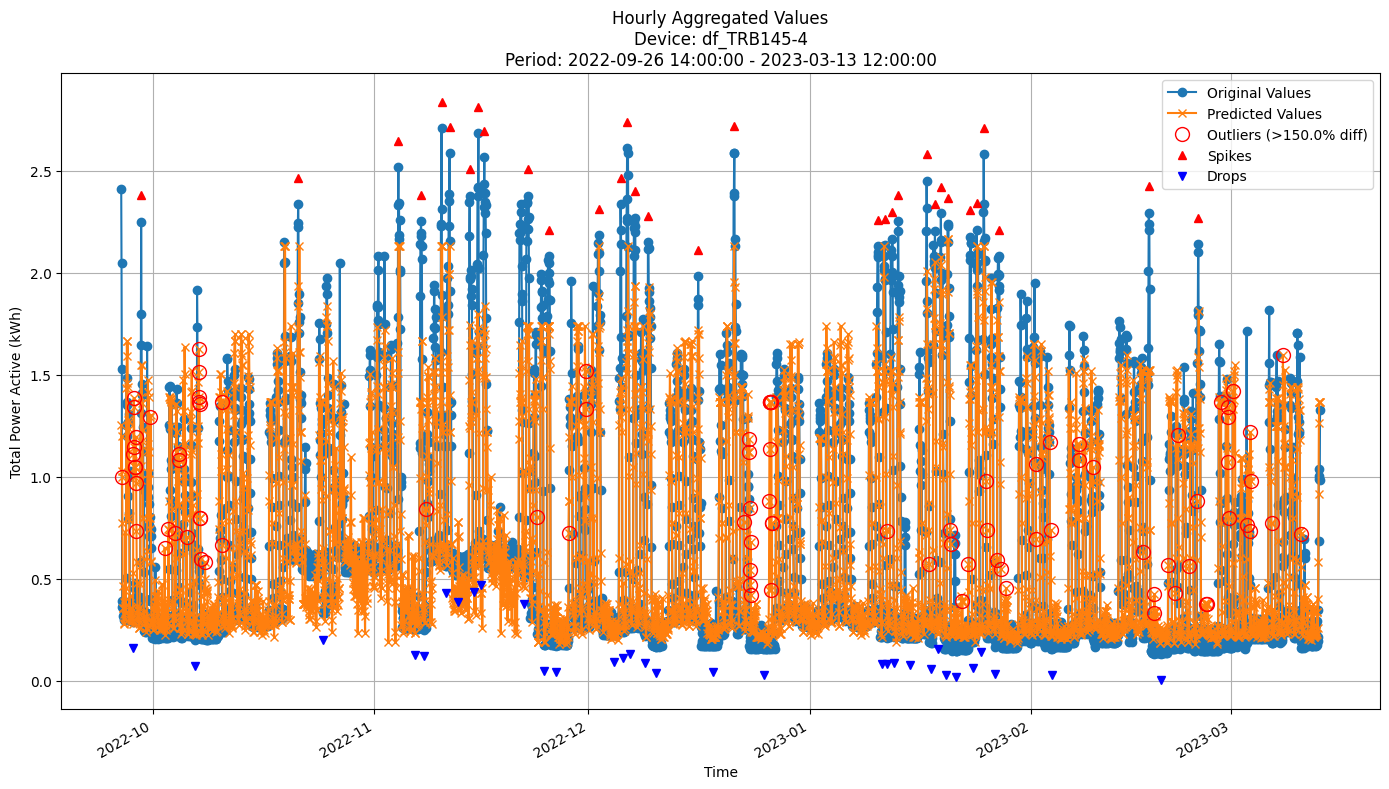


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.2645
MAE: 0.1694
MAPE: 31.8682%

Directional Metrics:
Directional Accuracy: 50.8063%
First-Diff Correlation: 0.4082

Immediate Detection (delta=0):
Spikes:
  Precision: 0.3125
  Recall: 0.1562
  F1 Score: 0.2083
Drops:
  Precision: 0.1579
  Recall: 0.0938
  F1 Score: 0.1176

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.5625
  Recall: 0.2812
  F1 Score: 0.3750
Drops:
  Precision: 0.1579
  Recall: 0.0938
  F1 Score: 0.1176


In [28]:
for device_id in hoef_all_train_preds.keys():
    y_train = hoef_all_train_preds[device_id][-1]['y_true']
    y_pred_train = hoef_all_train_preds[device_id][-1]['y_pred']

    # Plot hourly predictions
    plot_hourly_predictions(y_train,
                            y_pred_train,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last period of predictions

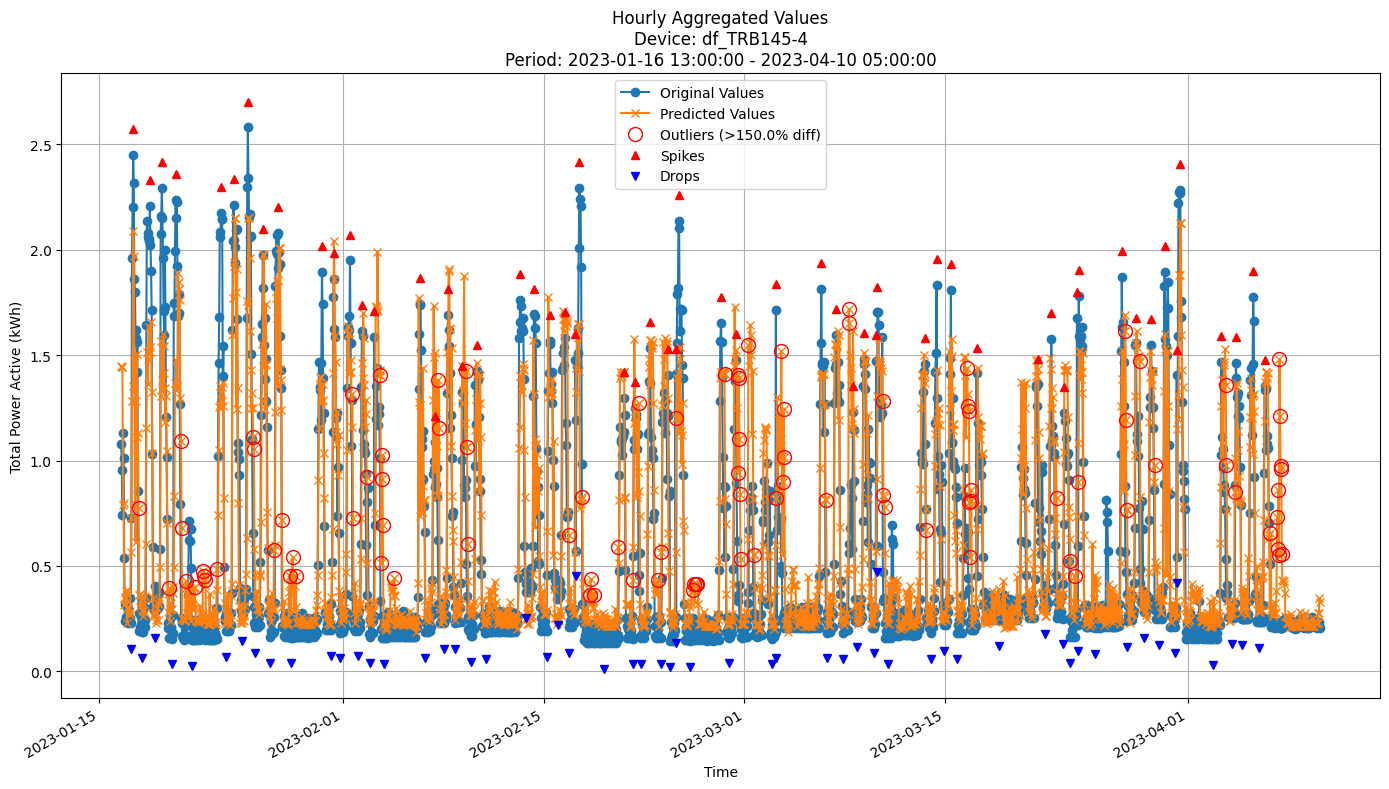


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.2935
MAE: 0.1870
MAPE: 42.9245%

Directional Metrics:
Directional Accuracy: 51.6193%
First-Diff Correlation: 0.3272

Immediate Detection (delta=0):
Spikes:
  Precision: 0.1053
  Recall: 0.1017
  F1 Score: 0.1034
Drops:
  Precision: 0.0351
  Recall: 0.0339
  F1 Score: 0.0345

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.3333
  Recall: 0.3220
  F1 Score: 0.3276
Drops:
  Precision: 0.0877
  Recall: 0.0847
  F1 Score: 0.0862


In [29]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in hoef_all_valid_preds.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, hoef_all_valid_preds[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, hoef_all_valid_preds[device_id][i]['y_pred']], axis=0)
    
    plot_hourly_predictions(y_valid, 
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY, 
                            device_id=device_id, 
                            outlier_threshold=1.5)

### ARF (Hoeffding Tree)

In [30]:
update_freq = "15min"  # for incremental models put the same as the data frequency to recreate real world scenario

arf_hf = ARFRegressor
arf_hf_params = dict(n_models=10, 
                     max_features=0.8, 
                     aggregation_method='median', 
                     grace_period=10, 
                     max_depth=10, 
                     delta=0.5, 
                     tau=0.01, 
                     seed=42)


In [ ]:

arf_hf_all_train_preds, arf_hf_all_valid_preds, \
arf_hf_all_train_metrics, arf_hf_all_valid_metrics = all_valid_splits_seq_fit_predict(
    model_class=arf_hf,
    model_params=arf_hf_params,
    train=train,
    valid=valid,
    use_residuals=USE_RESIDUAL,
    incremental=True,
    data_freq=DATA_FREQUENCY,
    forecast_horizon=FORECAST_HORIZON,
    features=ALL_FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE,
    start_split=0, 
    #end_split=4,  # Use only the third and fourth splits
    verbose=True
)

Processing splits:   0%|          | 0/6 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 79
Filtered feature count: 79
Excluded lag features: None
Valid features: ['hour', 'weekday', 'month', 'L1_act_power_lag_1h', 'L1_act_power_lag_24h', 'L1_act_power_lag_1455min', 'L1_act_power_lag_168h', 'L1_app_power_lag_1h', 'L1_app_power_lag_24h', 'L1_app_power_lag_1455min', 'L1_app_power_lag_168h', 'L1_current_lag_1h', 'L1_current_lag_24h', 'L1_current_lag_1455min', 'L1_current_lag_168h', 'L1_react_power_lag_1h', 'L1_react_power_lag_24h', 'L1_react_power_lag_1455min', 'L1_react_power_lag_168h', 'L1_voltage_lag_1h', 'L1_voltage_lag_24h', 'L1_voltage_lag_1455min', 'L1_voltage_lag_168h', 'L2_act_power_lag_1h', 'L2_act_power_lag_24h', 'L2_act_power_lag_1455min', 'L2_act_power_lag_168h', 'L2_app_power_lag_1h', 'L2_app_power_lag_24h', 'L2_app_power_lag_1455min', 'L2_app_power_lag_168h', 'L2_current_lag_1h', 'L2_current_lag_24h', 'L2_current_lag_1455min', 'L2_current_lag_168h', 'L2_react_power_lag_1h', 'L2_react_power_lag_2

Processing devices in split 1:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 79
Filtered feature count: 79
Excluded lag features: None
Valid features: ['hour', 'weekday', 'month', 'L1_act_power_lag_1h', 'L1_act_power_lag_24h', 'L1_act_power_lag_1455min', 'L1_act_power_lag_168h', 'L1_app_power_lag_1h', 'L1_app_power_lag_24h', 'L1_app_power_lag_1455min', 'L1_app_power_lag_168h', 'L1_current_lag_1h', 'L1_current_lag_24h', 'L1_current_lag_1455min', 'L1_current_lag_168h', 'L1_react_power_lag_1h', 'L1_react_power_lag_24h', 'L1_react_power_lag_1455min', 'L1_react_power_lag_168h', 'L1_voltage_lag_1h', 'L1_voltage_lag_24h', 'L1_voltage_lag_1455min', 'L1_voltage_lag_168h', 'L2_act_power_lag_1h', 'L2_act_power_lag_24h', 'L2_act_power_lag_1455min', 'L2_act_power_lag_168h', 'L2_app_power_lag_1h', 'L2_app_power_lag_24h', 'L2_app_power_lag_1455min', 'L2_app_power_lag_168h', 'L2_current_lag_1h', 'L2_current_lag_24h', 'L2_current_lag_1455min', 'L2_current_lag_168h', 'L2_react_power_lag_1h', 'L2_react_power_lag_2

Processing devices in split 2:   0%|          | 0/1 [00:00<?, ?it/s]

... (3 outputs left out)

Processing devices in split 4:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 79
Filtered feature count: 79
Excluded lag features: None
Valid features: ['hour', 'weekday', 'month', 'L1_act_power_lag_1h', 'L1_act_power_lag_24h', 'L1_act_power_lag_1455min', 'L1_act_power_lag_168h', 'L1_app_power_lag_1h', 'L1_app_power_lag_24h', 'L1_app_power_lag_1455min', 'L1_app_power_lag_168h', 'L1_current_lag_1h', 'L1_current_lag_24h', 'L1_current_lag_1455min', 'L1_current_lag_168h', 'L1_react_power_lag_1h', 'L1_react_power_lag_24h', 'L1_react_power_lag_1455min', 'L1_react_power_lag_168h', 'L1_voltage_lag_1h', 'L1_voltage_lag_24h', 'L1_voltage_lag_1455min', 'L1_voltage_lag_168h', 'L2_act_power_lag_1h', 'L2_act_power_lag_24h', 'L2_act_power_lag_1455min', 'L2_act_power_lag_168h', 'L2_app_power_lag_1h', 'L2_app_power_lag_24h', 'L2_app_power_lag_1455min', 'L2_app_power_lag_168h', 'L2_current_lag_1h', 'L2_current_lag_24h', 'L2_current_lag_1455min', 'L2_current_lag_168h', 'L2_react_power_lag_1h', 'L2_react_power_lag_2

Processing devices in split 5:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 79
Filtered feature count: 79
Excluded lag features: None
Valid features: ['hour', 'weekday', 'month', 'L1_act_power_lag_1h', 'L1_act_power_lag_24h', 'L1_act_power_lag_1455min', 'L1_act_power_lag_168h', 'L1_app_power_lag_1h', 'L1_app_power_lag_24h', 'L1_app_power_lag_1455min', 'L1_app_power_lag_168h', 'L1_current_lag_1h', 'L1_current_lag_24h', 'L1_current_lag_1455min', 'L1_current_lag_168h', 'L1_react_power_lag_1h', 'L1_react_power_lag_24h', 'L1_react_power_lag_1455min', 'L1_react_power_lag_168h', 'L1_voltage_lag_1h', 'L1_voltage_lag_24h', 'L1_voltage_lag_1455min', 'L1_voltage_lag_168h', 'L2_act_power_lag_1h', 'L2_act_power_lag_24h', 'L2_act_power_lag_1455min', 'L2_act_power_lag_168h', 'L2_app_power_lag_1h', 'L2_app_power_lag_24h', 'L2_app_power_lag_1455min', 'L2_app_power_lag_168h', 'L2_current_lag_1h', 'L2_current_lag_24h', 'L2_current_lag_1455min', 'L2_current_lag_168h', 'L2_react_power_lag_1h', 'L2_react_power_lag_2

#### Results

In [32]:
print("\n\nTrain period metrics:")
arf_hf_all_time_train_metrics = all_time_aggregation_metrics(arf_hf_all_train_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\Valid period metrics:")
arf_hf_all_time_valid_metrics = all_time_aggregation_metrics(arf_hf_all_valid_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: df_TRB145-4
--------------------------------------------------
15min Metrics:
	RMSE: 0.2626 ± 0.0116
	MAE: 0.1691 ± 0.0102
	MAPE: 31.8855% ± 2.0825%

	Directional Metrics:
		Directional Accuracy: 45.4567% ± 1.4125%
		First-Diff Correlation: 0.1467 ± 0.0171

	Immediate Detection (delta=0):
		Spike Precision: 0.0093 ± 0.0207
		Spike Recall: 0.0060 ± 0.0133
		Spike F1: 0.0072 ± 0.0162
		Drop Precision: 0.0000 ± 0.0000
		Drop Recall: 0.0000 ± 0.0000
		Drop F1: 0.0000 ± 0.0000

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.0718 ± 0.0827
		Spike Recall: 0.0719 ± 0.1190
		Spike F1: 0.0535 ± 0.0653
		Drop Precision: 0.0000 ± 0.0000
		Drop Recall: 0.0000 ± 0.0000
		Drop F1: 0.0000 ± 0.0000
Hourly Metrics:
	RMSE: 0.2395 ± 0.0105
	MAE: 0.1572 ± 0.0108
	MAPE: 28.6607% ± 2.6206%

	Directional Metrics:
		Directional Accuracy: 61.8970% ± 0.5891%
		First-Diff Correlation: 0.5221 ± 0.0464

	Immediate Detection (delta=0):

#### Training plots

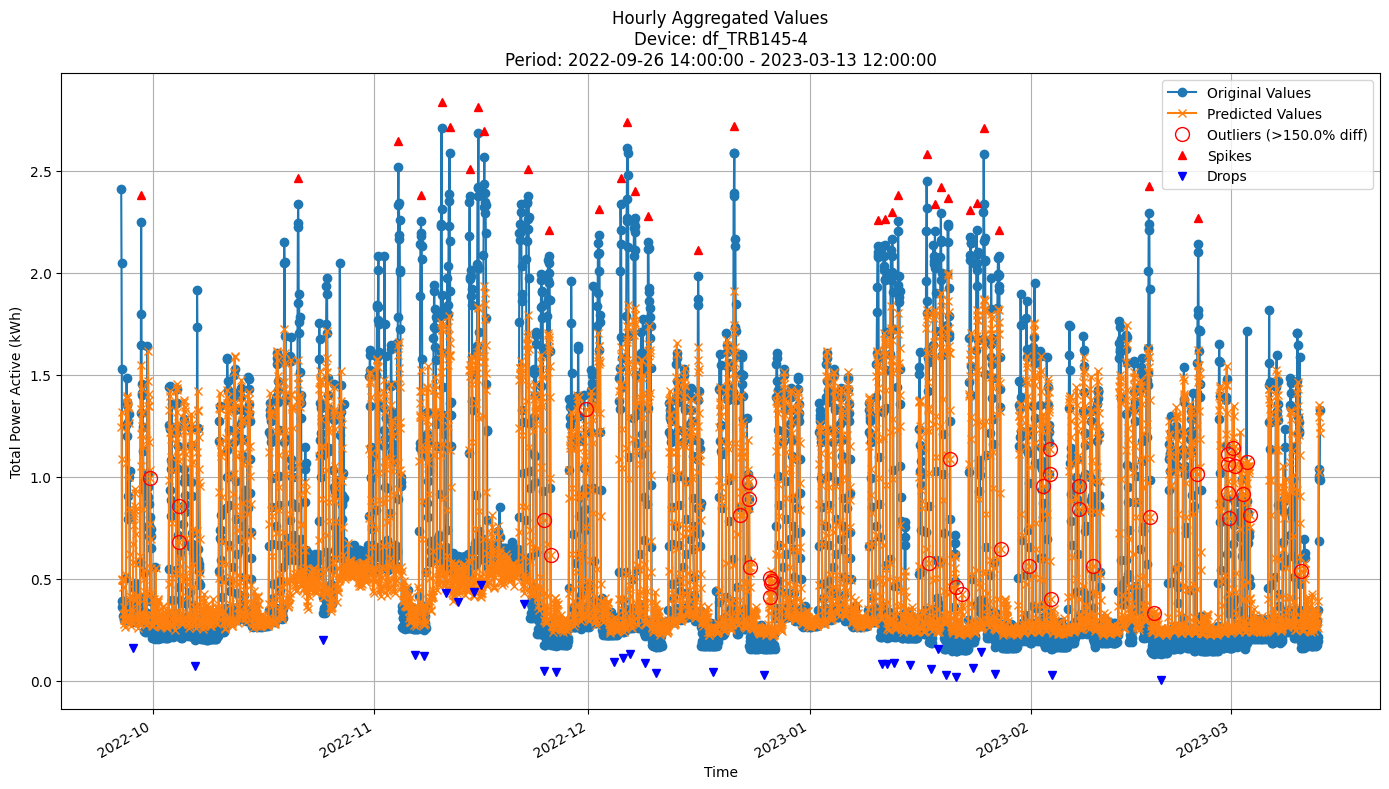


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.2334
MAE: 0.1453
MAPE: 26.6240%

Directional Metrics:
Directional Accuracy: 61.0518%
First-Diff Correlation: 0.5399

Immediate Detection (delta=0):
Spikes:
  Precision: 0.2500
  Recall: 0.0938
  F1 Score: 0.1364
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.6667
  Recall: 0.2500
  F1 Score: 0.3636
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


In [33]:
for device_id in arf_hf_all_train_preds.keys():
    y_train = arf_hf_all_train_preds[device_id][-1]['y_true']
    y_pred_train = arf_hf_all_train_preds[device_id][-1]['y_pred']

    # Plot hourly predictions
    plot_hourly_predictions(y_train,
                            y_pred_train, 
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last period of predictions

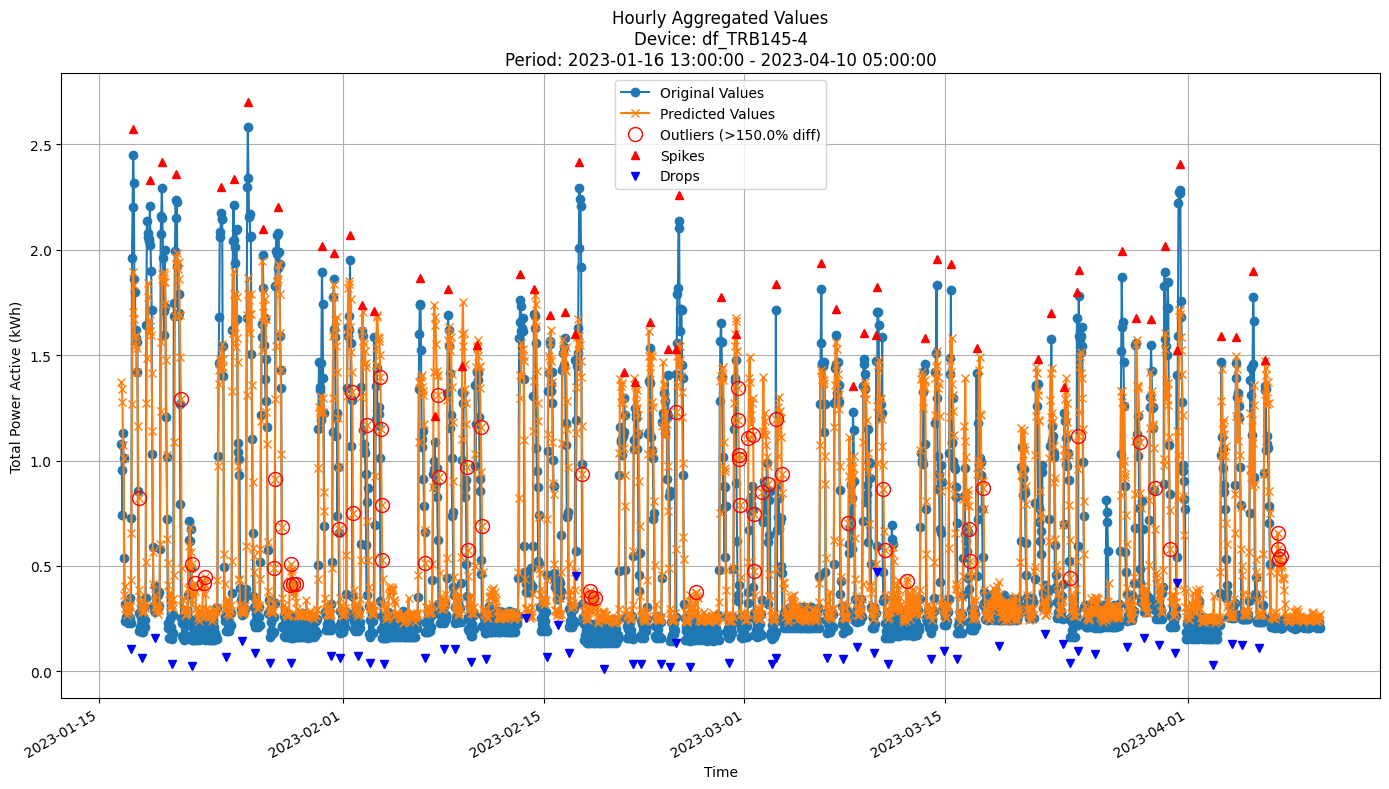


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.2466
MAE: 0.1629
MAPE: 39.9549%

Directional Metrics:
Directional Accuracy: 52.7653%
First-Diff Correlation: 0.3931

Immediate Detection (delta=0):
Spikes:
  Precision: 0.1207
  Recall: 0.1186
  F1 Score: 0.1197
Drops:
  Precision: 0.0172
  Recall: 0.0169
  F1 Score: 0.0171

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.4655
  Recall: 0.4576
  F1 Score: 0.4615
Drops:
  Precision: 0.1379
  Recall: 0.1356
  F1 Score: 0.1368


In [34]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in arf_hf_all_valid_preds.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, arf_hf_all_valid_preds[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, arf_hf_all_valid_preds[device_id][i]['y_pred']], axis=0)

    plot_hourly_predictions(y_valid,
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id,
                            outlier_threshold=1.5)

### FastODT

In [61]:
update_freq = "15min"  # for incremental models put the same as the data frequency to recreate real world scenario

fodt = fastodt.FastODT

fodt_params = {'depth': 50, 
               'grace_period': 24, 
               'grace_period_depth': 0, 
               'split_confidence': 0.005, 
               'max_feature': 1, 
               'tie_threshold': 0.05, 
               'bin_type': 'mean', 
               'split_criterion': 'vr_rel'}

# Results from hyperparam. tuning
# BEST RMSE: 0.284
#    Best Parameters: {'depth': 100, 'grace_period': 24, 'grace_period_depth': -1, 'split_confidence': 0.5, 'max_feature': 0.7, 'tie_threshold': 0.05, 'bin_type': 'mean', 'split_criterion': 'vr_rel'}
# BEST MAE: 0.166
#    Best Parameters: {'depth': 50, 'grace_period': 24, 'grace_period_depth': 0, 'split_confidence': 0.005, 'max_feature': 0.3, 'tie_threshold': 0.05, 'bin_type': 'mean', 'split_criterion': 'vr_rel'}
# BEST MAPE: 30.526%
#    Best Parameters: {'depth': 50, 'grace_period': 24, 'grace_period_depth': 0, 'split_confidence': 0.005, 'max_feature': 0.3, 'tie_threshold': 0.05, 'bin_type': 'mean', 'split_criterion': 'vr_rel'}
# BEST DIR_ACCURACY: 56.835%
#    Best Parameters: {'depth': 50, 'grace_period': 24, 'grace_period_depth': 0, 'split_confidence': 0.5, 'max_feature': 1.0, 'tie_threshold': 0.05, 'bin_type': 'mean', 'split_criterion': 'vr_rel'}
# BEST FIRST_DIFF_CORR: 39.216%
#    Best Parameters: {'depth': 5, 'grace_period': 96, 'grace_period_depth': 1, 'split_confidence': 0.005, 'max_feature': 1.0, 'tie_threshold': 0.05, 'bin_type': 'mean', 'split_criterion': 'vr_rel'}
# BEST SPIKES_F1: 28.855%
#    Best Parameters: {'depth': 5, 'grace_period': 10, 'grace_period_depth': 1, 'split_confidence': 0.5, 'max_feature': 0.5, 'tie_threshold': 0.05, 'bin_type': 'mean', 'split_criterion': 'vr_rel'}
# BEST DROPS_F1: 16.382%
#    Best Parameters: {'depth': 50, 'grace_period': 48, 'grace_period_depth': 0, 'split_confidence': 0.01, 'max_feature': 0.3, 'tie_threshold': 0.05, 'bin_type': 'mean', 'split_criterion': 'vr_rel'}

In [ ]:
fodt_all_train_preds, fodt_all_valid_preds, \
fodt_all_train_metrics, fodt_all_valid_metrics = all_valid_splits_seq_fit_predict(
    model_class=fodt, 
    model_params=fodt_params, 
    train=train, 
    valid=valid, 
    use_residuals=USE_RESIDUAL,
    incremental=True, 
    data_freq=DATA_FREQUENCY,
    forecast_horizon=FORECAST_HORIZON,
    features=ALL_FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE, 
    start_split=0, 
    #end_split=4,  # Use only the third and fourth splits
    verbose=True
)

Processing splits:   0%|          | 0/6 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 79
Filtered feature count: 79
Excluded lag features: None
Valid features: ['hour', 'weekday', 'month', 'L1_act_power_lag_1h', 'L1_act_power_lag_24h', 'L1_act_power_lag_1455min', 'L1_act_power_lag_168h', 'L1_app_power_lag_1h', 'L1_app_power_lag_24h', 'L1_app_power_lag_1455min', 'L1_app_power_lag_168h', 'L1_current_lag_1h', 'L1_current_lag_24h', 'L1_current_lag_1455min', 'L1_current_lag_168h', 'L1_react_power_lag_1h', 'L1_react_power_lag_24h', 'L1_react_power_lag_1455min', 'L1_react_power_lag_168h', 'L1_voltage_lag_1h', 'L1_voltage_lag_24h', 'L1_voltage_lag_1455min', 'L1_voltage_lag_168h', 'L2_act_power_lag_1h', 'L2_act_power_lag_24h', 'L2_act_power_lag_1455min', 'L2_act_power_lag_168h', 'L2_app_power_lag_1h', 'L2_app_power_lag_24h', 'L2_app_power_lag_1455min', 'L2_app_power_lag_168h', 'L2_current_lag_1h', 'L2_current_lag_24h', 'L2_current_lag_1455min', 'L2_current_lag_168h', 'L2_react_power_lag_1h', 'L2_react_power_lag_2

Processing devices in split 1:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 79
Filtered feature count: 79
Excluded lag features: None
Valid features: ['hour', 'weekday', 'month', 'L1_act_power_lag_1h', 'L1_act_power_lag_24h', 'L1_act_power_lag_1455min', 'L1_act_power_lag_168h', 'L1_app_power_lag_1h', 'L1_app_power_lag_24h', 'L1_app_power_lag_1455min', 'L1_app_power_lag_168h', 'L1_current_lag_1h', 'L1_current_lag_24h', 'L1_current_lag_1455min', 'L1_current_lag_168h', 'L1_react_power_lag_1h', 'L1_react_power_lag_24h', 'L1_react_power_lag_1455min', 'L1_react_power_lag_168h', 'L1_voltage_lag_1h', 'L1_voltage_lag_24h', 'L1_voltage_lag_1455min', 'L1_voltage_lag_168h', 'L2_act_power_lag_1h', 'L2_act_power_lag_24h', 'L2_act_power_lag_1455min', 'L2_act_power_lag_168h', 'L2_app_power_lag_1h', 'L2_app_power_lag_24h', 'L2_app_power_lag_1455min', 'L2_app_power_lag_168h', 'L2_current_lag_1h', 'L2_current_lag_24h', 'L2_current_lag_1455min', 'L2_current_lag_168h', 'L2_react_power_lag_1h', 'L2_react_power_lag_2

Processing devices in split 2:   0%|          | 0/1 [00:00<?, ?it/s]

... (3 outputs left out)

Processing devices in split 4:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 79
Filtered feature count: 79
Excluded lag features: None
Valid features: ['hour', 'weekday', 'month', 'L1_act_power_lag_1h', 'L1_act_power_lag_24h', 'L1_act_power_lag_1455min', 'L1_act_power_lag_168h', 'L1_app_power_lag_1h', 'L1_app_power_lag_24h', 'L1_app_power_lag_1455min', 'L1_app_power_lag_168h', 'L1_current_lag_1h', 'L1_current_lag_24h', 'L1_current_lag_1455min', 'L1_current_lag_168h', 'L1_react_power_lag_1h', 'L1_react_power_lag_24h', 'L1_react_power_lag_1455min', 'L1_react_power_lag_168h', 'L1_voltage_lag_1h', 'L1_voltage_lag_24h', 'L1_voltage_lag_1455min', 'L1_voltage_lag_168h', 'L2_act_power_lag_1h', 'L2_act_power_lag_24h', 'L2_act_power_lag_1455min', 'L2_act_power_lag_168h', 'L2_app_power_lag_1h', 'L2_app_power_lag_24h', 'L2_app_power_lag_1455min', 'L2_app_power_lag_168h', 'L2_current_lag_1h', 'L2_current_lag_24h', 'L2_current_lag_1455min', 'L2_current_lag_168h', 'L2_react_power_lag_1h', 'L2_react_power_lag_2

Processing devices in split 5:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 79
Filtered feature count: 79
Excluded lag features: None
Valid features: ['hour', 'weekday', 'month', 'L1_act_power_lag_1h', 'L1_act_power_lag_24h', 'L1_act_power_lag_1455min', 'L1_act_power_lag_168h', 'L1_app_power_lag_1h', 'L1_app_power_lag_24h', 'L1_app_power_lag_1455min', 'L1_app_power_lag_168h', 'L1_current_lag_1h', 'L1_current_lag_24h', 'L1_current_lag_1455min', 'L1_current_lag_168h', 'L1_react_power_lag_1h', 'L1_react_power_lag_24h', 'L1_react_power_lag_1455min', 'L1_react_power_lag_168h', 'L1_voltage_lag_1h', 'L1_voltage_lag_24h', 'L1_voltage_lag_1455min', 'L1_voltage_lag_168h', 'L2_act_power_lag_1h', 'L2_act_power_lag_24h', 'L2_act_power_lag_1455min', 'L2_act_power_lag_168h', 'L2_app_power_lag_1h', 'L2_app_power_lag_24h', 'L2_app_power_lag_1455min', 'L2_app_power_lag_168h', 'L2_current_lag_1h', 'L2_current_lag_24h', 'L2_current_lag_1455min', 'L2_current_lag_168h', 'L2_react_power_lag_1h', 'L2_react_power_lag_2

#### Results

In [63]:
print("\n\nTrain period metrics:")
fodt_all_time_train_metrics = all_time_aggregation_metrics(fodt_all_train_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\Valid period metrics:")
fodt_all_time_valid_metrics = all_time_aggregation_metrics(fodt_all_valid_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: df_TRB145-4
--------------------------------------------------
15min Metrics:
	RMSE: 0.4093 ± 0.0555
	MAE: 0.2632 ± 0.0461
	MAPE: 48.1552% ± 13.4287%

	Directional Metrics:
		Directional Accuracy: 21.9172% ± 5.8671%
		First-Diff Correlation: 0.0470 ± 0.0201

	Immediate Detection (delta=0):
		Spike Precision: 0.0060 ± 0.0089
		Spike Recall: 0.0386 ± 0.0498
		Spike F1: 0.0098 ± 0.0139
		Drop Precision: 0.0047 ± 0.0068
		Drop Recall: 0.0200 ± 0.0286
		Drop F1: 0.0077 ± 0.0110

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.0168 ± 0.0200
		Spike Recall: 0.0951 ± 0.1002
		Spike F1: 0.0271 ± 0.0313
		Drop Precision: 0.0190 ± 0.0272
		Drop Recall: 0.1144 ± 0.1268
		Drop F1: 0.0311 ± 0.0436
Hourly Metrics:
	RMSE: 0.3590 ± 0.0588
	MAE: 0.2362 ± 0.0501
	MAPE: 42.6313% ± 14.6049%

	Directional Metrics:
		Directional Accuracy: 51.0904% ± 7.0984%
		First-Diff Correlation: 0.3144 ± 0.0518

	Immediate Detection (delta=0

#### Training plots


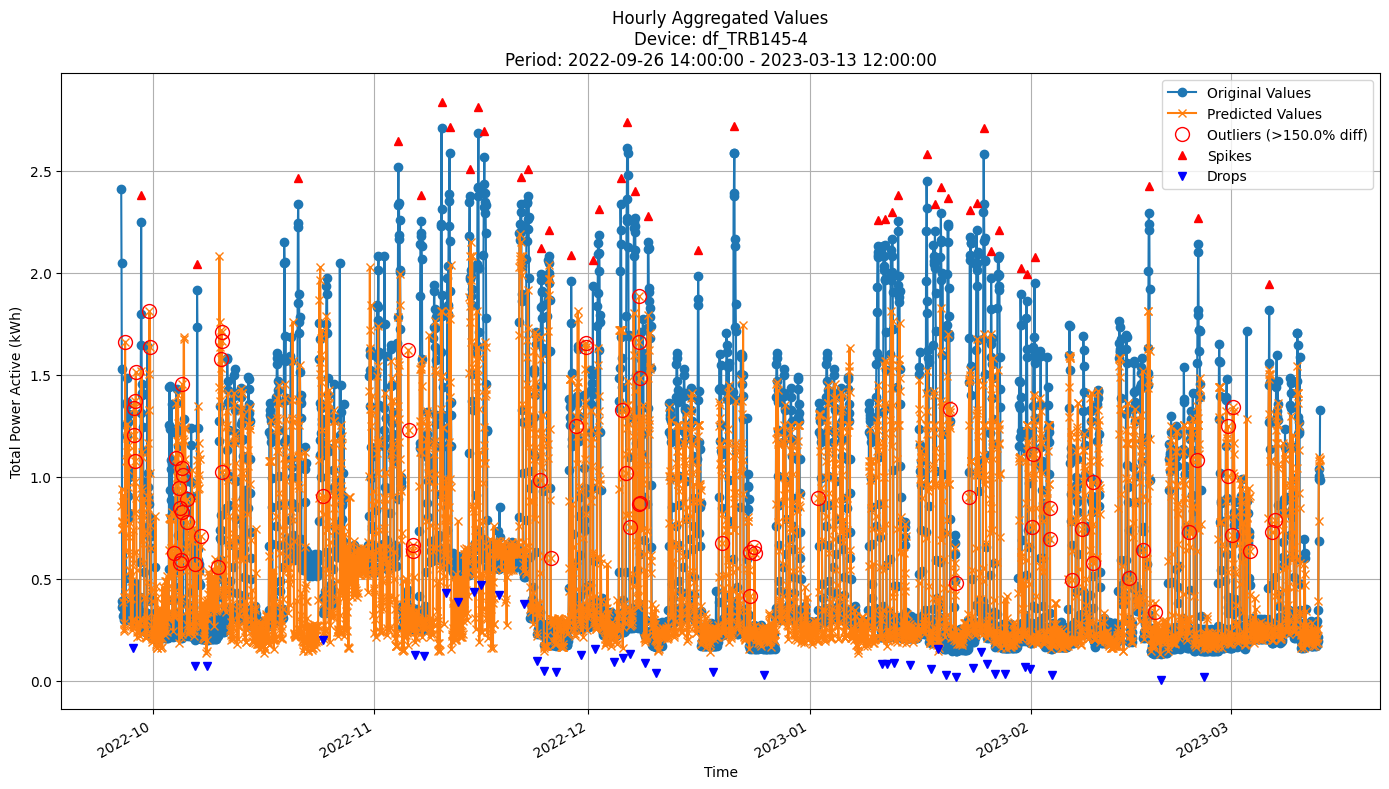


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.3299
MAE: 0.1980
MAPE: 30.7628%

Directional Metrics:
Directional Accuracy: 55.4949%
First-Diff Correlation: 0.3588

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0444
  Recall: 0.0476
  F1 Score: 0.0460
Drops:
  Precision: 0.0800
  Recall: 0.0952
  F1 Score: 0.0870

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.1556
  Recall: 0.1667
  F1 Score: 0.1609
Drops:
  Precision: 0.1200
  Recall: 0.1429
  F1 Score: 0.1304


In [64]:
for device_id in fodt_all_train_preds.keys():
    y_train = fodt_all_train_preds[device_id][-1]['y_true']
    y_pred_train = fodt_all_train_preds[device_id][-1]['y_pred']
    
    # Plot hourly predictions
    plot_hourly_predictions(y_train,
                            y_pred_train,
                            data_freq=DATA_FREQUENCY, 
                            device_id=device_id,
                            spike_prominence=SPIKE_PROMINENCE, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last period of predictions

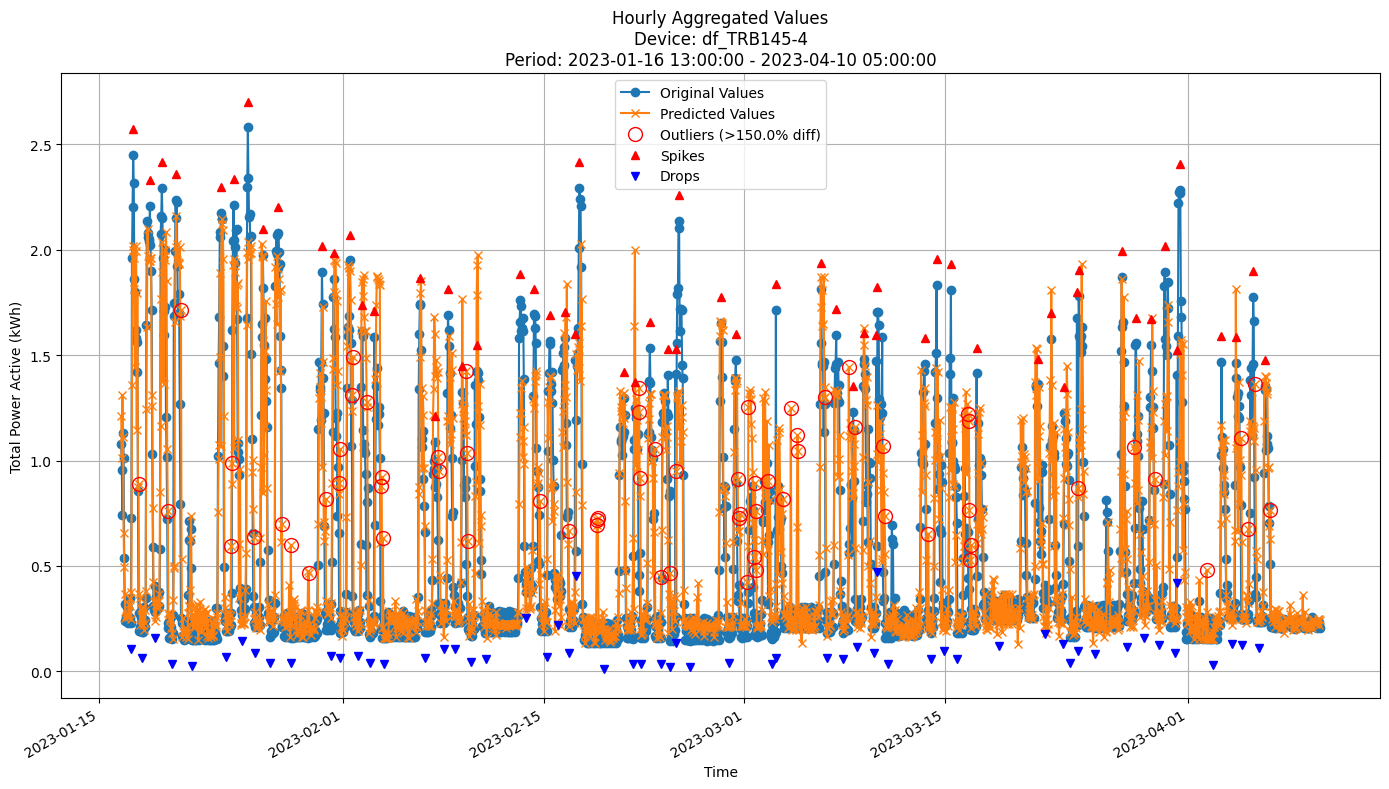


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.2815
MAE: 0.1679
MAPE: 34.6617%

Directional Metrics:
Directional Accuracy: 53.5127%
First-Diff Correlation: 0.2821

Immediate Detection (delta=0):
Spikes:
  Precision: 0.1667
  Recall: 0.1864
  F1 Score: 0.1760
Drops:
  Precision: 0.1538
  Recall: 0.1695
  F1 Score: 0.1613

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.3182
  Recall: 0.3559
  F1 Score: 0.3360
Drops:
  Precision: 0.3077
  Recall: 0.3390
  F1 Score: 0.3226


In [65]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in fodt_all_valid_preds.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, fodt_all_valid_preds[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, fodt_all_valid_preds[device_id][i]['y_pred']], axis=0)
    
    plot_hourly_predictions(y_valid, 
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY, 
                            device_id=device_id, 
                            outlier_threshold=1.5)

### ARF (FastODT)

In [40]:
update_freq = "15min"  # for incremental models put the same as the data frequency to recreate real world scenario

arf = ARFRegressorFODT
arf_params = dict(n_models=20, 
                  aggregation_method="mean", 
                  grace_period=0,  # by default works for all leaves
                  disable_weighted_vote=True,
                  max_depth=50, 
                  delta=0.05, 
                  tau=0.01, 
                  seed=42, 
                  max_features=0.7, 
                  bin_type='mean', 
                  max_bins=1,
                  split_criterion='vr_rel',)


In [ ]:

arf_all_train_preds, arf_all_valid_preds, \
arf_all_train_metrics, arf_all_valid_metrics = all_valid_splits_seq_fit_predict(
    model_class=arf,
    model_params=arf_params,
    train=train,
    valid=valid,
    use_residuals=USE_RESIDUAL,
    incremental=True,
    data_freq=DATA_FREQUENCY,
    forecast_horizon=FORECAST_HORIZON,
    features=ALL_FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE,
    start_split=0,
    #end_split=4,  # Use only the third and fourth splits
    verbose=True
)

Processing splits:   0%|          | 0/6 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 79
Filtered feature count: 79
Excluded lag features: None
Valid features: ['hour', 'weekday', 'month', 'L1_act_power_lag_1h', 'L1_act_power_lag_24h', 'L1_act_power_lag_1455min', 'L1_act_power_lag_168h', 'L1_app_power_lag_1h', 'L1_app_power_lag_24h', 'L1_app_power_lag_1455min', 'L1_app_power_lag_168h', 'L1_current_lag_1h', 'L1_current_lag_24h', 'L1_current_lag_1455min', 'L1_current_lag_168h', 'L1_react_power_lag_1h', 'L1_react_power_lag_24h', 'L1_react_power_lag_1455min', 'L1_react_power_lag_168h', 'L1_voltage_lag_1h', 'L1_voltage_lag_24h', 'L1_voltage_lag_1455min', 'L1_voltage_lag_168h', 'L2_act_power_lag_1h', 'L2_act_power_lag_24h', 'L2_act_power_lag_1455min', 'L2_act_power_lag_168h', 'L2_app_power_lag_1h', 'L2_app_power_lag_24h', 'L2_app_power_lag_1455min', 'L2_app_power_lag_168h', 'L2_current_lag_1h', 'L2_current_lag_24h', 'L2_current_lag_1455min', 'L2_current_lag_168h', 'L2_react_power_lag_1h', 'L2_react_power_lag_2

Processing devices in split 1:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 79
Filtered feature count: 79
Excluded lag features: None
Valid features: ['hour', 'weekday', 'month', 'L1_act_power_lag_1h', 'L1_act_power_lag_24h', 'L1_act_power_lag_1455min', 'L1_act_power_lag_168h', 'L1_app_power_lag_1h', 'L1_app_power_lag_24h', 'L1_app_power_lag_1455min', 'L1_app_power_lag_168h', 'L1_current_lag_1h', 'L1_current_lag_24h', 'L1_current_lag_1455min', 'L1_current_lag_168h', 'L1_react_power_lag_1h', 'L1_react_power_lag_24h', 'L1_react_power_lag_1455min', 'L1_react_power_lag_168h', 'L1_voltage_lag_1h', 'L1_voltage_lag_24h', 'L1_voltage_lag_1455min', 'L1_voltage_lag_168h', 'L2_act_power_lag_1h', 'L2_act_power_lag_24h', 'L2_act_power_lag_1455min', 'L2_act_power_lag_168h', 'L2_app_power_lag_1h', 'L2_app_power_lag_24h', 'L2_app_power_lag_1455min', 'L2_app_power_lag_168h', 'L2_current_lag_1h', 'L2_current_lag_24h', 'L2_current_lag_1455min', 'L2_current_lag_168h', 'L2_react_power_lag_1h', 'L2_react_power_lag_2

Processing devices in split 2:   0%|          | 0/1 [00:00<?, ?it/s]

... (3 outputs left out)

Processing devices in split 4:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 79
Filtered feature count: 79
Excluded lag features: None
Valid features: ['hour', 'weekday', 'month', 'L1_act_power_lag_1h', 'L1_act_power_lag_24h', 'L1_act_power_lag_1455min', 'L1_act_power_lag_168h', 'L1_app_power_lag_1h', 'L1_app_power_lag_24h', 'L1_app_power_lag_1455min', 'L1_app_power_lag_168h', 'L1_current_lag_1h', 'L1_current_lag_24h', 'L1_current_lag_1455min', 'L1_current_lag_168h', 'L1_react_power_lag_1h', 'L1_react_power_lag_24h', 'L1_react_power_lag_1455min', 'L1_react_power_lag_168h', 'L1_voltage_lag_1h', 'L1_voltage_lag_24h', 'L1_voltage_lag_1455min', 'L1_voltage_lag_168h', 'L2_act_power_lag_1h', 'L2_act_power_lag_24h', 'L2_act_power_lag_1455min', 'L2_act_power_lag_168h', 'L2_app_power_lag_1h', 'L2_app_power_lag_24h', 'L2_app_power_lag_1455min', 'L2_app_power_lag_168h', 'L2_current_lag_1h', 'L2_current_lag_24h', 'L2_current_lag_1455min', 'L2_current_lag_168h', 'L2_react_power_lag_1h', 'L2_react_power_lag_2

Processing devices in split 5:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 79
Filtered feature count: 79
Excluded lag features: None
Valid features: ['hour', 'weekday', 'month', 'L1_act_power_lag_1h', 'L1_act_power_lag_24h', 'L1_act_power_lag_1455min', 'L1_act_power_lag_168h', 'L1_app_power_lag_1h', 'L1_app_power_lag_24h', 'L1_app_power_lag_1455min', 'L1_app_power_lag_168h', 'L1_current_lag_1h', 'L1_current_lag_24h', 'L1_current_lag_1455min', 'L1_current_lag_168h', 'L1_react_power_lag_1h', 'L1_react_power_lag_24h', 'L1_react_power_lag_1455min', 'L1_react_power_lag_168h', 'L1_voltage_lag_1h', 'L1_voltage_lag_24h', 'L1_voltage_lag_1455min', 'L1_voltage_lag_168h', 'L2_act_power_lag_1h', 'L2_act_power_lag_24h', 'L2_act_power_lag_1455min', 'L2_act_power_lag_168h', 'L2_app_power_lag_1h', 'L2_app_power_lag_24h', 'L2_app_power_lag_1455min', 'L2_app_power_lag_168h', 'L2_current_lag_1h', 'L2_current_lag_24h', 'L2_current_lag_1455min', 'L2_current_lag_168h', 'L2_react_power_lag_1h', 'L2_react_power_lag_2

#### Results

In [42]:
print("\n\nTrain period metrics:")
arf_all_time_train_metrics = all_time_aggregation_metrics(arf_all_train_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\Valid period metrics:")
arf_all_time_valid_metrics = all_time_aggregation_metrics(arf_all_valid_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: df_TRB145-4
--------------------------------------------------
15min Metrics:
	RMSE: 0.3953 ± 0.0544
	MAE: 0.2722 ± 0.0584
	MAPE: 51.7980% ± 25.2561%

	Directional Metrics:
		Directional Accuracy: 51.2009% ± 2.4068%
		First-Diff Correlation: 0.1083 ± 0.0091

	Immediate Detection (delta=0):
		Spike Precision: 0.0117 ± 0.0115
		Spike Recall: 0.0710 ± 0.0872
		Spike F1: 0.0192 ± 0.0192
		Drop Precision: 0.0013 ± 0.0029
		Drop Recall: 0.0030 ± 0.0067
		Drop F1: 0.0018 ± 0.0041

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.0242 ± 0.0220
		Spike Recall: 0.1162 ± 0.0970
		Spike F1: 0.0385 ± 0.0332
		Drop Precision: 0.0153 ± 0.0099
		Drop Recall: 0.1095 ± 0.0902
		Drop F1: 0.0264 ± 0.0180
Hourly Metrics:
	RMSE: 0.3715 ± 0.0580
	MAE: 0.2576 ± 0.0600
	MAPE: 47.9375% ± 25.1163%

	Directional Metrics:
		Directional Accuracy: 61.5101% ± 2.8424%
		First-Diff Correlation: 0.4813 ± 0.0513

	Immediate Detection (delta=0

#### Training plots

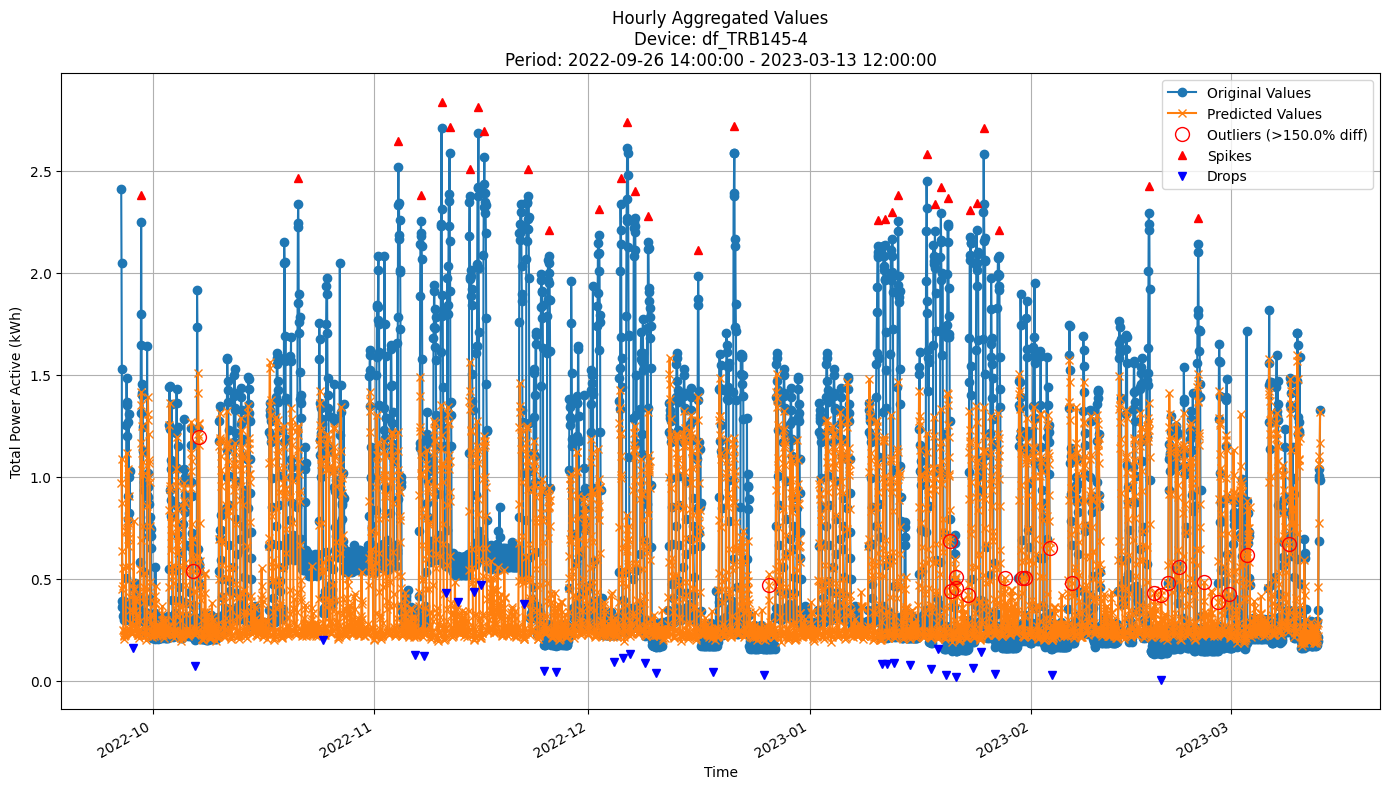


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.3804
MAE: 0.2363
MAPE: 33.3133%

Directional Metrics:
Directional Accuracy: 58.1742%
First-Diff Correlation: 0.4939

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0748
  Recall: 0.2500
  F1 Score: 0.1151
Drops:
  Precision: 0.0092
  Recall: 0.0312
  F1 Score: 0.0142

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.1589
  Recall: 0.5312
  F1 Score: 0.2446
Drops:
  Precision: 0.0642
  Recall: 0.2188
  F1 Score: 0.0993


In [43]:
for device_id in arf_all_train_preds.keys():
    y_train = arf_all_train_preds[device_id][-1]['y_true']
    y_pred_train = arf_all_train_preds[device_id][-1]['y_pred']

    # Plot hourly predictions
    plot_hourly_predictions(y_train,
                            y_pred_train, 
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last period of predictions

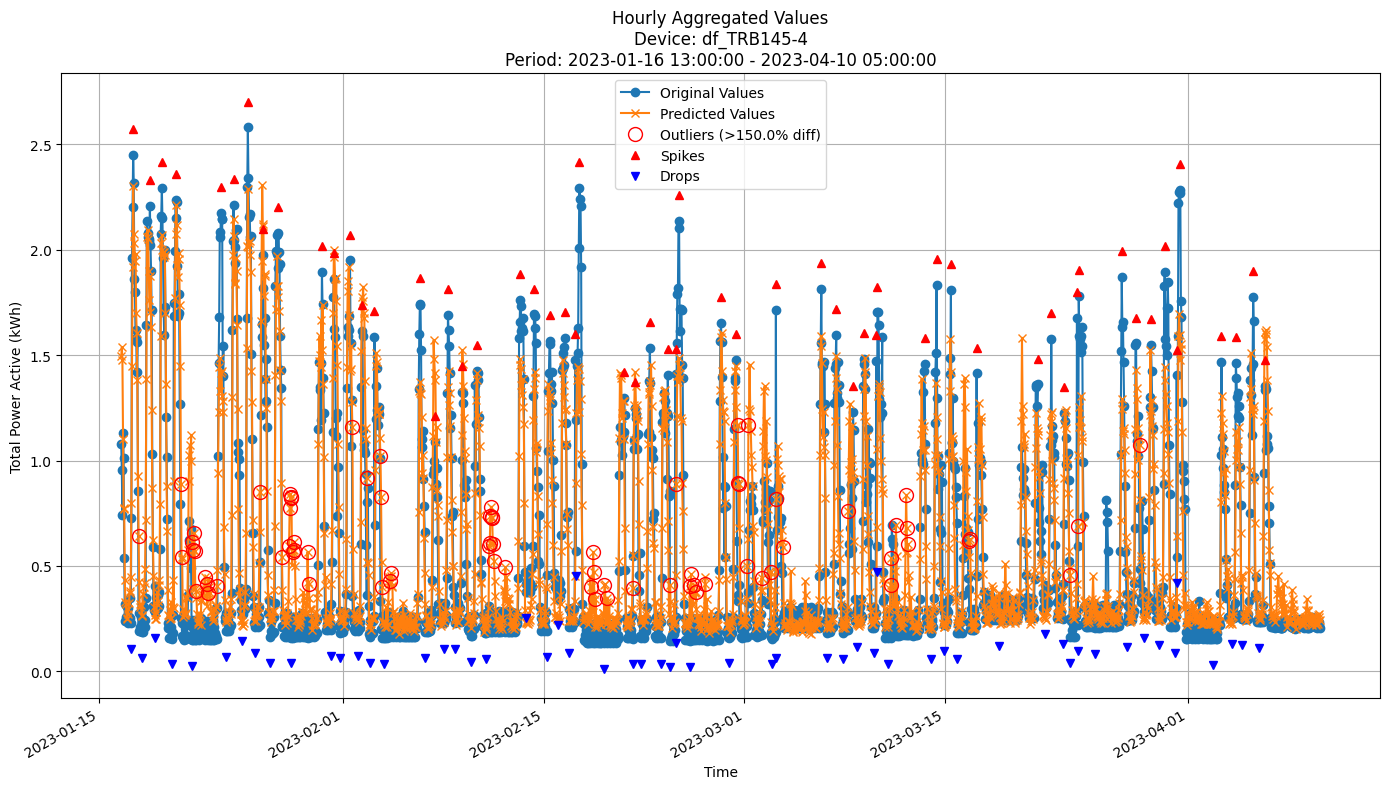


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.2324
MAE: 0.1524
MAPE: 36.9733%

Directional Metrics:
Directional Accuracy: 54.0608%
First-Diff Correlation: 0.4639

Immediate Detection (delta=0):
Spikes:
  Precision: 0.2642
  Recall: 0.2373
  F1 Score: 0.2500
Drops:
  Precision: 0.0377
  Recall: 0.0339
  F1 Score: 0.0357

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.4906
  Recall: 0.4407
  F1 Score: 0.4643
Drops:
  Precision: 0.2453
  Recall: 0.2203
  F1 Score: 0.2321


In [44]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in arf_all_valid_preds.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, arf_all_valid_preds[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, arf_all_valid_preds[device_id][i]['y_pred']], axis=0)

    plot_hourly_predictions(y_valid,
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id,
                            outlier_threshold=1.5)

### iNcubation Boost

In [45]:
update_freq = "15min"  # for incremental models put the same as the data frequency to recreate real world scenario:

split_confidence_hf = 0.01
grace_period = 24
depth = 50
eagerness = 0
bin_type = 'mean'  # 'mean' or 'adaptive'
max_bins = 1
# max_bins = 32  # for adaptive binning
max_features = 0.7
tie_threshold = 0.05
grace_period_depth = -1 # set to 1 to use only for first node, set to -1 to use for all nodes, set to N to use for N nodes

incb = IncubationBoost
incb_params = dict(
    length=20,
    learning_rate=0.5,
    depth=depth,
    grace_period=grace_period,
    split_confidence=split_confidence_hf,
    eagerness=eagerness,
    grace_period_depth=grace_period_depth,
    bin_type=bin_type,
    max_bins=max_bins,
    max_feature=max_features,
    tie_threshold=tie_threshold,
    split_criterion='vr_rel',
    verbose=False
)

# Results from hyperparam. tuning (might need to UPDATE after new drift detection method)
# BEST RMSE: 0.357
#    Best Parameters: {'baseLearner': <class 'src.trees.fastodt.FastODT'>, 'length': 70, 'learning_rate': 1.0, 'incubationMode': 'DEFAULT', 'baseLearnerOptions': (15, 10, 0.005, 'hf', 1.0, 1000, 0), 'verbose': False}
# BEST MAE: 0.276
#    Best Parameters: {'baseLearner': <class 'src.trees.fastodt.FastODT'>, 'length': 70, 'learning_rate': 1.0, 'incubationMode': 'DEFAULT', 'baseLearnerOptions': (15, 10, 0.005, 'hf', 1.0, 1000, 0), 'verbose': False}
# BEST MAPE: 61.889%
#    Best Parameters: {'baseLearner': <class 'src.trees.fastodt.FastODT'>, 'length': 50, 'learning_rate': 1.0, 'incubationMode': 'DEFAULT', 'baseLearnerOptions': (70, 10, 0.005, 'hf', 1.0, 1000, 0), 'verbose': False}
# BEST DIR_ACCURACY: 60.316%
#    Best Parameters: {'baseLearner': <class 'src.trees.fastodt.FastODT'>, 'length': 50, 'learning_rate': 1.0, 'incubationMode': 'DEFAULT', 'baseLearnerOptions': (50, 10, 0.005, 'hf', 1.0, 1000, 0), 'verbose': False}
# BEST FIRST_DIFF_CORR: 49.973%
#    Best Parameters: {'baseLearner': <class 'src.trees.fastodt.FastODT'>, 'length': 50, 'learning_rate': 1.0, 'incubationMode': 'DEFAULT', 'baseLearnerOptions': (50, 10, 0.005, 'hf', 1.0, 1000, 0), 'verbose': False}
# BEST SPIKES_F1: 6.190%
#    Best Parameters: {'baseLearner': <class 'src.trees.fastodt.FastODT'>, 'length': 50, 'learning_rate': 1.0, 'incubationMode': 'DEFAULT', 'baseLearnerOptions': (15, 10, 0.005, 'hf', 1.0, 1000, 0), 'verbose': False}
# BEST DROPS_F1: 0.000%
#    Best Parameters: {'baseLearner': <class 'src.trees.fastodt.FastODT'>, 'length': 50, 'learning_rate': 1.0, 'incubationMode': 'DEFAULT', 'baseLearnerOptions': (15, 10, 0.005, 'hf', 1.0, 1000, 0), 'verbose': False}

In [ ]:
incb_all_train_preds, incb_all_valid_preds, \
incb_all_train_metrics, incb_all_valid_metrics = all_valid_splits_seq_fit_predict(
    model_class=incb, 
    model_params=incb_params, 
    train=train, 
    valid=valid, 
    use_residuals=USE_RESIDUAL,
    incremental=True, 
    data_freq=DATA_FREQUENCY,
    forecast_horizon=FORECAST_HORIZON,
    features=ALL_FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE, 
    start_split=0, 
    # end_split=1,  # Use only the third and fourth splits
    verbose=True
)

Processing splits:   0%|          | 0/6 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 79
Filtered feature count: 79
Excluded lag features: None
Valid features: ['hour', 'weekday', 'month', 'L1_act_power_lag_1h', 'L1_act_power_lag_24h', 'L1_act_power_lag_1455min', 'L1_act_power_lag_168h', 'L1_app_power_lag_1h', 'L1_app_power_lag_24h', 'L1_app_power_lag_1455min', 'L1_app_power_lag_168h', 'L1_current_lag_1h', 'L1_current_lag_24h', 'L1_current_lag_1455min', 'L1_current_lag_168h', 'L1_react_power_lag_1h', 'L1_react_power_lag_24h', 'L1_react_power_lag_1455min', 'L1_react_power_lag_168h', 'L1_voltage_lag_1h', 'L1_voltage_lag_24h', 'L1_voltage_lag_1455min', 'L1_voltage_lag_168h', 'L2_act_power_lag_1h', 'L2_act_power_lag_24h', 'L2_act_power_lag_1455min', 'L2_act_power_lag_168h', 'L2_app_power_lag_1h', 'L2_app_power_lag_24h', 'L2_app_power_lag_1455min', 'L2_app_power_lag_168h', 'L2_current_lag_1h', 'L2_current_lag_24h', 'L2_current_lag_1455min', 'L2_current_lag_168h', 'L2_react_power_lag_1h', 'L2_react_power_lag_2

Processing devices in split 1:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 79
Filtered feature count: 79
Excluded lag features: None
Valid features: ['hour', 'weekday', 'month', 'L1_act_power_lag_1h', 'L1_act_power_lag_24h', 'L1_act_power_lag_1455min', 'L1_act_power_lag_168h', 'L1_app_power_lag_1h', 'L1_app_power_lag_24h', 'L1_app_power_lag_1455min', 'L1_app_power_lag_168h', 'L1_current_lag_1h', 'L1_current_lag_24h', 'L1_current_lag_1455min', 'L1_current_lag_168h', 'L1_react_power_lag_1h', 'L1_react_power_lag_24h', 'L1_react_power_lag_1455min', 'L1_react_power_lag_168h', 'L1_voltage_lag_1h', 'L1_voltage_lag_24h', 'L1_voltage_lag_1455min', 'L1_voltage_lag_168h', 'L2_act_power_lag_1h', 'L2_act_power_lag_24h', 'L2_act_power_lag_1455min', 'L2_act_power_lag_168h', 'L2_app_power_lag_1h', 'L2_app_power_lag_24h', 'L2_app_power_lag_1455min', 'L2_app_power_lag_168h', 'L2_current_lag_1h', 'L2_current_lag_24h', 'L2_current_lag_1455min', 'L2_current_lag_168h', 'L2_react_power_lag_1h', 'L2_react_power_lag_2

Processing devices in split 2:   0%|          | 0/1 [00:00<?, ?it/s]

... (3 outputs left out)

Processing devices in split 4:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 79
Filtered feature count: 79
Excluded lag features: None
Valid features: ['hour', 'weekday', 'month', 'L1_act_power_lag_1h', 'L1_act_power_lag_24h', 'L1_act_power_lag_1455min', 'L1_act_power_lag_168h', 'L1_app_power_lag_1h', 'L1_app_power_lag_24h', 'L1_app_power_lag_1455min', 'L1_app_power_lag_168h', 'L1_current_lag_1h', 'L1_current_lag_24h', 'L1_current_lag_1455min', 'L1_current_lag_168h', 'L1_react_power_lag_1h', 'L1_react_power_lag_24h', 'L1_react_power_lag_1455min', 'L1_react_power_lag_168h', 'L1_voltage_lag_1h', 'L1_voltage_lag_24h', 'L1_voltage_lag_1455min', 'L1_voltage_lag_168h', 'L2_act_power_lag_1h', 'L2_act_power_lag_24h', 'L2_act_power_lag_1455min', 'L2_act_power_lag_168h', 'L2_app_power_lag_1h', 'L2_app_power_lag_24h', 'L2_app_power_lag_1455min', 'L2_app_power_lag_168h', 'L2_current_lag_1h', 'L2_current_lag_24h', 'L2_current_lag_1455min', 'L2_current_lag_168h', 'L2_react_power_lag_1h', 'L2_react_power_lag_2

Processing devices in split 5:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 79
Filtered feature count: 79
Excluded lag features: None
Valid features: ['hour', 'weekday', 'month', 'L1_act_power_lag_1h', 'L1_act_power_lag_24h', 'L1_act_power_lag_1455min', 'L1_act_power_lag_168h', 'L1_app_power_lag_1h', 'L1_app_power_lag_24h', 'L1_app_power_lag_1455min', 'L1_app_power_lag_168h', 'L1_current_lag_1h', 'L1_current_lag_24h', 'L1_current_lag_1455min', 'L1_current_lag_168h', 'L1_react_power_lag_1h', 'L1_react_power_lag_24h', 'L1_react_power_lag_1455min', 'L1_react_power_lag_168h', 'L1_voltage_lag_1h', 'L1_voltage_lag_24h', 'L1_voltage_lag_1455min', 'L1_voltage_lag_168h', 'L2_act_power_lag_1h', 'L2_act_power_lag_24h', 'L2_act_power_lag_1455min', 'L2_act_power_lag_168h', 'L2_app_power_lag_1h', 'L2_app_power_lag_24h', 'L2_app_power_lag_1455min', 'L2_app_power_lag_168h', 'L2_current_lag_1h', 'L2_current_lag_24h', 'L2_current_lag_1455min', 'L2_current_lag_168h', 'L2_react_power_lag_1h', 'L2_react_power_lag_2

#### Results

In [47]:
print("\n\nTrain period metrics:")
incb_all_time_train_metrics = all_time_aggregation_metrics(incb_all_train_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\nValid period metrics:")
incb_all_time_valid_metrics = all_time_aggregation_metrics(incb_all_valid_metrics, data_freq=DATA_FREQUENCY, verbose=True)
# Hourly Metrics:
# 	RMSE: 0.4348 ± 0.1387
# 	MAE: 0.3140 ± 0.0869
# 	MAPE: 60.2407% ± 12.6513%
# 	Dir Accuracy: 57.2071% ± 2.1944%
# 	First-Diff Correlation: 0.3343 ± 0.0699



Train period metrics:


Aggregated Metrics Across Periods
Device ID: df_TRB145-4
--------------------------------------------------
15min Metrics:
	RMSE: 0.5327 ± 0.0654
	MAE: 0.3719 ± 0.0522
	MAPE: 49.5592% ± 6.3448%

	Directional Metrics:
		Directional Accuracy: 17.5403% ± 4.2802%
		First-Diff Correlation: 0.0540 ± 0.0276

	Immediate Detection (delta=0):
		Spike Precision: 0.0029 ± 0.0042
		Spike Recall: 0.0097 ± 0.0142
		Spike F1: 0.0045 ± 0.0065
		Drop Precision: 0.0015 ± 0.0022
		Drop Recall: 0.0067 ± 0.0095
		Drop F1: 0.0025 ± 0.0035

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.0084 ± 0.0111
		Spike Recall: 0.0419 ± 0.0464
		Spike F1: 0.0133 ± 0.0171
		Drop Precision: 0.0081 ± 0.0086
		Drop Recall: 0.0654 ± 0.0891
		Drop F1: 0.0139 ± 0.0147
Hourly Metrics:
	RMSE: 0.5186 ± 0.0661
	MAE: 0.3641 ± 0.0535
	MAPE: 47.8371% ± 7.0061%

	Directional Metrics:
		Directional Accuracy: 46.6492% ± 7.8637%
		First-Diff Correlation: 0.2621 ± 0.0778

	Immediate Detection (delta=0):

#### Train plots

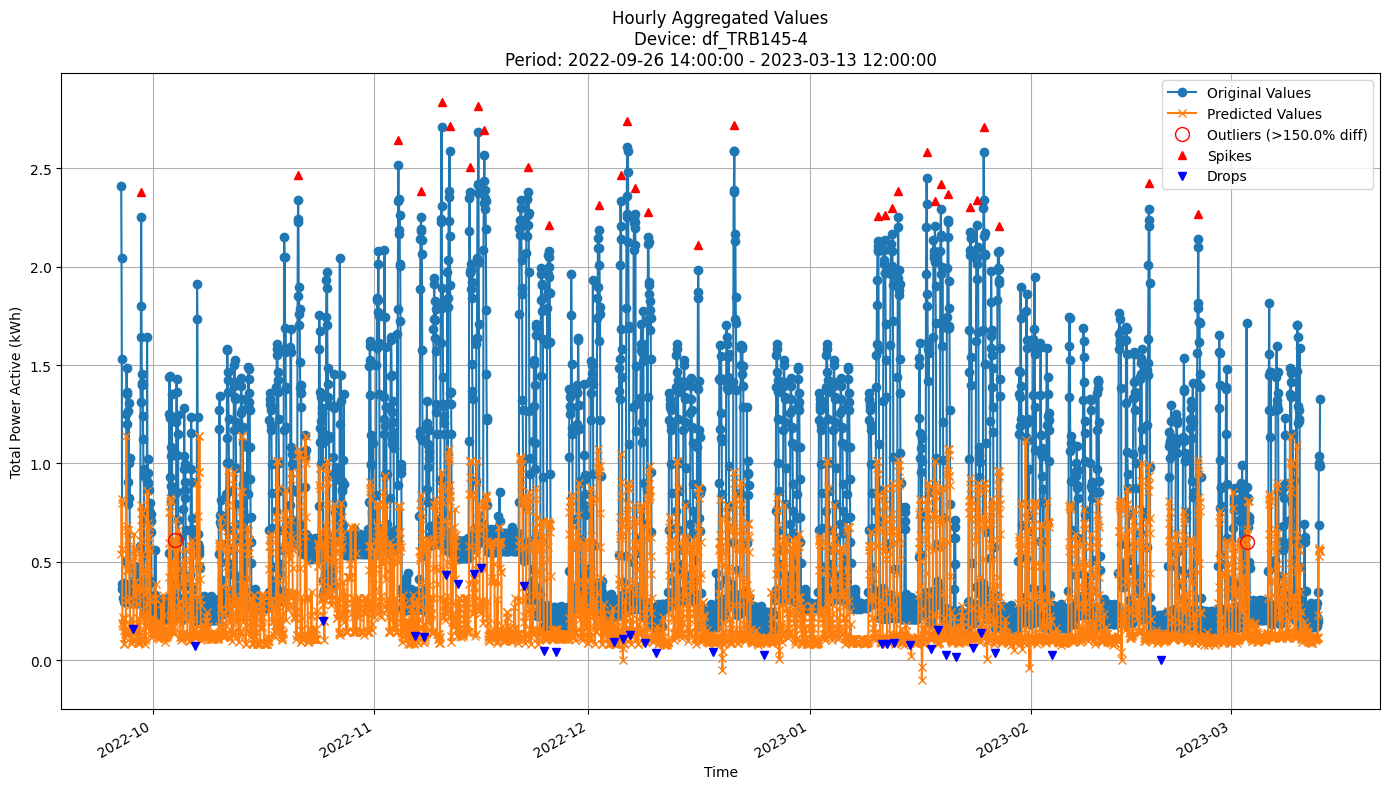


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.5232
MAE: 0.3663
MAPE: 50.8763%

Directional Metrics:
Directional Accuracy: 53.0389%
First-Diff Correlation: 0.2245

Immediate Detection (delta=0):
Spikes:
  Precision: 0.2000
  Recall: 0.2188
  F1 Score: 0.2090
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.2857
  Recall: 0.3125
  F1 Score: 0.2985
Drops:
  Precision: 0.1053
  Recall: 0.1250
  F1 Score: 0.1143


In [48]:
for device_id in incb_all_train_preds.keys():
    y_train = incb_all_train_preds[device_id][-1]['y_true']
    y_pred_train = incb_all_train_preds[device_id][-1]['y_pred']
    plot_hourly_predictions(y_train, 
                            y_pred_train, 
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last period of predictions

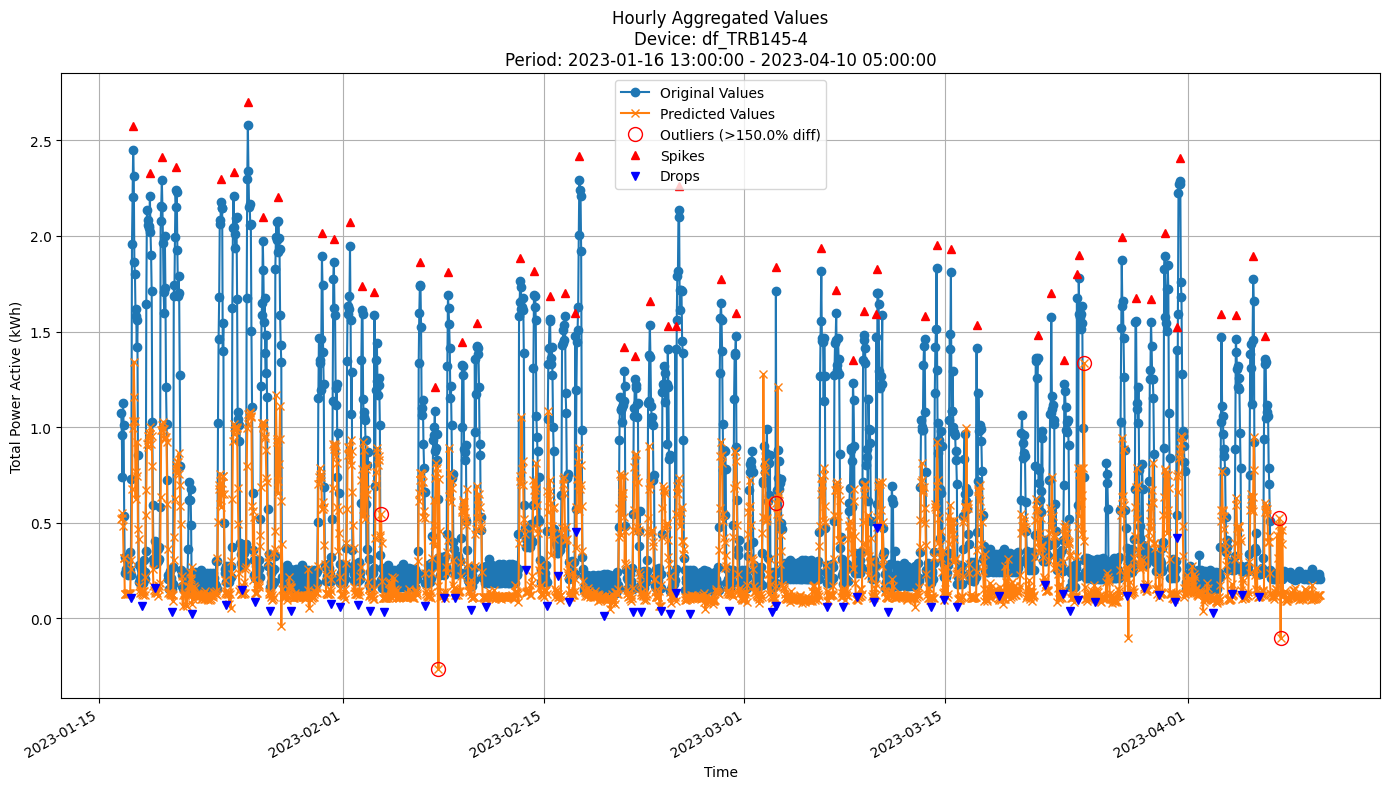


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.4307
MAE: 0.2837
MAPE: 46.3146%

Directional Metrics:
Directional Accuracy: 55.8545%
First-Diff Correlation: 0.2023

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0492
  Recall: 0.0508
  F1 Score: 0.0500
Drops:
  Precision: 0.0484
  Recall: 0.0508
  F1 Score: 0.0496

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.3607
  Recall: 0.3729
  F1 Score: 0.3667
Drops:
  Precision: 0.1774
  Recall: 0.1864
  F1 Score: 0.1818


In [49]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in incb_all_valid_preds.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, incb_all_valid_preds[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, incb_all_valid_preds[device_id][i]['y_pred']], axis=0)

    plot_hourly_predictions(y_valid,
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id,
                            outlier_threshold=1.5)

# Test-set Model Evaluation
(`train[-1]` + `valid[-1]`) vs `test`

In [ ]:
# Initialize the models and params for test-set evaluation
models_classes = [bl_prev, bl_mean, gbdt, rf, hoef, arf_hf, fodt, arf, incb]
models_params = [bl_prev_params, bl_mean_params, gbdt_params, rf_params,
                 hoef_params, arf_hf_params, fodt_params, arf_params, incb_params]

model_test_results = {}
for model, params in zip(models_classes, models_params):
    if model in [gbdt, rf, bl_mean]:
        # Batch learning models
        incremental = False
        update_freq = "14D"
        print(f"\n\n\nModel: {model.__name__} - update_freq: {update_freq}")
    else:
        # Incremental learning models
        incremental = True
        update_freq = "15m"
        print(f"\n\n\nModel: {model.__name__} - update_freq: {update_freq}")

    _, test_preds, \
    _, test_metrics = test_set_seq_fit_predict(
        model_class=model,
        model_params=params,
        train=train, 
        valid=valid,
        test=test,
        use_residuals=USE_RESIDUAL,
        incremental=incremental, 
        data_freq=DATA_FREQUENCY,
        forecast_horizon=FORECAST_HORIZON,
        features=ALL_FEATURES,
        update_freq=update_freq,
        spike_prominence=SPIKE_PROMINENCE,
        normalize_robust=True,
        predict_train=False,
        verbose=1
    )
    model_test_results[model.__name__] = {
        "test_preds": test_preds,
        "test_metrics": test_metrics
    }




Model: PreviousValueRegressor - update_freq: 15m


Processing devices for test predictions:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 79
Filtered feature count: 79
Excluded lag features: None
Valid features: ['hour', 'weekday', 'month', 'L1_act_power_lag_1h', 'L1_act_power_lag_24h', 'L1_act_power_lag_1455min', 'L1_act_power_lag_168h', 'L1_app_power_lag_1h', 'L1_app_power_lag_24h', 'L1_app_power_lag_1455min', 'L1_app_power_lag_168h', 'L1_current_lag_1h', 'L1_current_lag_24h', 'L1_current_lag_1455min', 'L1_current_lag_168h', 'L1_react_power_lag_1h', 'L1_react_power_lag_24h', 'L1_react_power_lag_1455min', 'L1_react_power_lag_168h', 'L1_voltage_lag_1h', 'L1_voltage_lag_24h', 'L1_voltage_lag_1455min', 'L1_voltage_lag_168h', 'L2_act_power_lag_1h', 'L2_act_power_lag_24h', 'L2_act_power_lag_1455min', 'L2_act_power_lag_168h', 'L2_app_power_lag_1h', 'L2_app_power_lag_24h', 'L2_app_power_lag_1455min', 'L2_app_power_lag_168h', 'L2_current_lag_1h', 'L2_current_lag_24h', 'L2_current_lag_1455min', 'L2_current_lag_168h', 'L2_react_power_lag_1h', 'L2_react_power_lag_2

Processing devices for test predictions:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2022-09-26 14:15:00+02:00 to 2023-04-10 05:30:00+02:00

Time: 0.03 seconds
Predicting for chunk from 2023-04-10 06:00:00+02:00 to 2023-04-24 06:00:00+02:00

-------------------------

Retraining model on data from 2022-09-26 14:15:00+02:00 to 2023-04-24 06:00:00+02:00

Time: 0.03 seconds
Predicting for chunk from 2023-04-24 06:15:00+02:00 to 2023-05-08 06:15:00+02:00

-------------------------

Retraining model on data from 2022-09-26 14:15:00+02:00 to 2023-05-08 06:15:00+02:00

Time: 0.03 seconds
Predicting for chunk from 2023-05-08 06:30:00+02:00 to 2023-05-22 06:30:00+02:00

-------------------------

Retraining model on data from 2022-09-26 14:15:00+02:00 to 2023-05-22 06:30:00+02:00

Time: 0.04 seconds
Predicting for chunk from 2023-05-22 06:45:00+02:00 to 2023-05-30 21:30:00+02:00

-------------------------
Model's memory usage: 0.024323 MB
Metrics for Device: df_TRB145-4 | Period: 2023-04-10 06:00:00+02:00 - 2023-05-30 21:30:00+02:00
15min Metrics:

Processing devices for test predictions:   0%|          | 0/1 [00:00<?, ?it/s]

... (9 outputs left out)

Processing devices for test predictions:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 79
Filtered feature count: 79
Excluded lag features: None
Valid features: ['hour', 'weekday', 'month', 'L1_act_power_lag_1h', 'L1_act_power_lag_24h', 'L1_act_power_lag_1455min', 'L1_act_power_lag_168h', 'L1_app_power_lag_1h', 'L1_app_power_lag_24h', 'L1_app_power_lag_1455min', 'L1_app_power_lag_168h', 'L1_current_lag_1h', 'L1_current_lag_24h', 'L1_current_lag_1455min', 'L1_current_lag_168h', 'L1_react_power_lag_1h', 'L1_react_power_lag_24h', 'L1_react_power_lag_1455min', 'L1_react_power_lag_168h', 'L1_voltage_lag_1h', 'L1_voltage_lag_24h', 'L1_voltage_lag_1455min', 'L1_voltage_lag_168h', 'L2_act_power_lag_1h', 'L2_act_power_lag_24h', 'L2_act_power_lag_1455min', 'L2_act_power_lag_168h', 'L2_app_power_lag_1h', 'L2_app_power_lag_24h', 'L2_app_power_lag_1455min', 'L2_app_power_lag_168h', 'L2_current_lag_1h', 'L2_current_lag_24h', 'L2_current_lag_1455min', 'L2_current_lag_168h', 'L2_react_power_lag_1h', 'L2_react_power_lag_2

Processing devices for test predictions:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 79
Filtered feature count: 79
Excluded lag features: None
Valid features: ['hour', 'weekday', 'month', 'L1_act_power_lag_1h', 'L1_act_power_lag_24h', 'L1_act_power_lag_1455min', 'L1_act_power_lag_168h', 'L1_app_power_lag_1h', 'L1_app_power_lag_24h', 'L1_app_power_lag_1455min', 'L1_app_power_lag_168h', 'L1_current_lag_1h', 'L1_current_lag_24h', 'L1_current_lag_1455min', 'L1_current_lag_168h', 'L1_react_power_lag_1h', 'L1_react_power_lag_24h', 'L1_react_power_lag_1455min', 'L1_react_power_lag_168h', 'L1_voltage_lag_1h', 'L1_voltage_lag_24h', 'L1_voltage_lag_1455min', 'L1_voltage_lag_168h', 'L2_act_power_lag_1h', 'L2_act_power_lag_24h', 'L2_act_power_lag_1455min', 'L2_act_power_lag_168h', 'L2_app_power_lag_1h', 'L2_app_power_lag_24h', 'L2_app_power_lag_1455min', 'L2_app_power_lag_168h', 'L2_current_lag_1h', 'L2_current_lag_24h', 'L2_current_lag_1455min', 'L2_current_lag_168h', 'L2_react_power_lag_1h', 'L2_react_power_lag_2

In [68]:
for model in models_classes:
    model_test_results[model.__name__]['test_metrics'] = all_time_aggregation_metrics(
        model_test_results[model.__name__]['test_metrics'],
        data_freq=DATA_FREQUENCY,
        verbose=False)

# Model Comparison

In [69]:
AGG_LEVEL = "hourly"
METRICS = ["rmse", "mae", "mape", "dir_accuracy", "first_diff_corr"]
PERC_METRICS = ["mape", "dir_accuracy", "first_diff_corr"]
# SPIKES_METRICS = ["spikes_immediate.precision", "spikes_immediate.recall", "spikes_immediate.f1",
#                   "spikes_delayed.precision", "spikes_delayed.recall", "spikes_delayed.f1",
#                   "drops_immediate.precision", "drops_immediate.recall", "drops_immediate.f1",
#                   "drops_delayed.precision", "drops_delayed.recall", "drops_delayed.f1"]
SPIKES_METRICS = ["spikes_immediate.f1", "spikes_delayed.f1",
                  "drops_immediate.f1", "drops_delayed.f1"]

METRICS.extend(SPIKES_METRICS)
PERC_METRICS.extend(SPIKES_METRICS)

## Test results

In [70]:
MODEL_TEST_METRICS = {
    "BL_Prev": model_test_results[bl_prev.__name__]["test_metrics"],
    "BL_Mean": model_test_results[bl_mean.__name__]["test_metrics"],
    "GBDT": model_test_results[gbdt.__name__]["test_metrics"],
    "RandomForest": model_test_results[rf.__name__]["test_metrics"],
    "HoeffdingTree": model_test_results[hoef.__name__]["test_metrics"],
    "ARF_Hoeffding": model_test_results[arf_hf.__name__]["test_metrics"],
    "FastODT": model_test_results[fodt.__name__]["test_metrics"],
    "ARF_FastODT": model_test_results[arf.__name__]["test_metrics"],
    "IncubationBoost": model_test_results[incb.__name__]["test_metrics"],
}

In [71]:
def format_metric(val, is_perc=False):
    if isinstance(val, dict) and "mean" in val and "std" in val:
        mean = val["mean"]
        std = val["std"]
        if is_perc:
            mean = mean * 100
            std = std * 100
        return f"{mean:.3f} ± {std:.3f}"
    if is_perc:
        return f"{val*100:.3f}" if val is not None else None
    return f"{val:.3f}" if val is not None else None

def display_aggregated_results(model_metrics, device_ids, agg_level):
    for device_id in device_ids:
        rows = []
        for model, mdict in model_metrics.items():
            if device_id in mdict and agg_level in mdict[device_id]:
                vals = mdict[device_id][agg_level]
                row = [model]
                for m in METRICS:
                    is_perc = (m in PERC_METRICS)
                    row.append(format_metric(vals.get(m, None), is_perc=is_perc))
                rows.append(row)
        df = pd.DataFrame(rows, columns=["Model", "RMSE", "MAE", "MAPE (%)", "Directional Accuracy (%)", "First Diff Corr (%)",
                                         "Spikes Immediate F1 (%)", "Spikes Delayed F1 (%)", "Drops Immediate F1 (%)", "Drops Delayed F1 (%)"])
        print(f"\n\nDevice: {device_id} | Aggregation: {agg_level}")
        display(df)

In [72]:
device_ids = set()
for m in MODEL_TEST_METRICS.values():
    device_ids.update(m.keys())
device_ids = sorted(device_ids)

print("\n============================15-Min Test Results============================")
display_aggregated_results(MODEL_TEST_METRICS, device_ids, "15min")
print("\n\n============================Hourly Test Results============================")
display_aggregated_results(MODEL_TEST_METRICS, device_ids, "hourly")


============================15-Min Test Results============================


Device: df_TRB145-4 | Aggregation: 15min


,Model,RMSE,MAE,MAPE (%),Directional Accuracy (%),First Diff Corr (%),Spikes Immediate F1 (%),Spikes Delayed F1 (%),Drops Immediate F1 (%),Drops Delayed F1 (%)
0,BL_Prev,0.227 ± 0.000,0.095 ± 0.000,18.996 ± 0.000,9.996 ± 0.000,-17.751 ± 0.000,4.211 ± 0.000,31.579 ± 0.000,0.000 ± 0.000,4.301 ± 0.000
1,BL_Mean,0.349 ± 0.000,0.222 ± 0.000,55.598 ± 0.000,13.204 ± 0.000,5.859 ± 0.000,4.651 ± 0.000,11.628 ± 0.000,0.000 ± 0.000,2.381 ± 0.000
2,GBDT,0.212 ± 0.000,0.129 ± 0.000,29.417 ± 0.000,51.687 ± 0.000,17.263 ± 0.000,6.122 ± 0.000,20.408 ± 0.000,4.167 ± 0.000,10.417 ± 0.000
3,RandomForest,0.229 ± 0.000,0.132 ± 0.000,28.090 ± 0.000,52.838 ± 0.000,17.466 ± 0.000,6.742 ± 0.000,13.483 ± 0.000,9.091 ± 0.000,13.636 ± 0.000
4,HoeffdingTree,0.319 ± 0.000,0.186 ± 0.000,39.423 ± 0.000,26.903 ± 0.000,6.492 ± 0.000,0.000 ± 0.000,6.667 ± 0.000,0.000 ± 0.000,1.754 ± 0.000
5,ARF_Hoeffding,0.263 ± 0.000,0.149 ± 0.000,30.220 ± 0.000,46.915 ± 0.000,6.274 ± 0.000,0.000 ± 0.000,4.348 ± 0.000,0.000 ± 0.000,2.247 ± 0.000
6,FastODT,0.340 ± 0.000,0.168 ± 0.000,31.988 ± 0.000,37.310 ± 0.000,-3.692 ± 0.000,6.498 ± 0.000,15.884 ± 0.000,1.370 ± 0.000,4.795 ± 0.000
7,ARF_FastODT,0.251 ± 0.000,0.134 ± 0.000,25.062 ± 0.000,51.501 ± 0.000,5.339 ± 0.000,7.477 ± 0.000,20.561 ± 0.000,0.000 ± 0.000,1.905 ± 0.000
8,IncubationBoost,0.423 ± 0.000,0.278 ± 0.000,49.635 ± 0.000,27.993 ± 0.000,9.190 ± 0.000,4.734 ± 0.000,15.385 ± 0.000,2.381 ± 0.000,7.143 ± 0.000




============================Hourly Test Results============================


Device: df_TRB145-4 | Aggregation: hourly


,Model,RMSE,MAE,MAPE (%),Directional Accuracy (%),First Diff Corr (%),Spikes Immediate F1 (%),Spikes Delayed F1 (%),Drops Immediate F1 (%),Drops Delayed F1 (%)
0,BL_Prev,0.167 ± 0.000,0.076 ± 0.000,13.770 ± 0.000,64.856 ± 0.000,35.648 ± 0.000,17.391 ± 0.000,89.130 ± 0.000,15.556 ± 0.000,37.778 ± 0.000
1,BL_Mean,0.334 ± 0.000,0.212 ± 0.000,52.160 ± 0.000,60.494 ± 0.000,42.136 ± 0.000,19.048 ± 0.000,59.524 ± 0.000,19.512 ± 0.000,31.707 ± 0.000
2,GBDT,0.182 ± 0.000,0.116 ± 0.000,26.148 ± 0.000,55.062 ± 0.000,52.194 ± 0.000,4.938 ± 0.000,61.728 ± 0.000,5.063 ± 0.000,12.658 ± 0.000
3,RandomForest,0.205 ± 0.000,0.118 ± 0.000,24.397 ± 0.000,58.107 ± 0.000,48.437 ± 0.000,9.756 ± 0.000,60.976 ± 0.000,7.500 ± 0.000,25.000 ± 0.000
4,HoeffdingTree,0.287 ± 0.000,0.166 ± 0.000,35.125 ± 0.000,55.226 ± 0.000,39.538 ± 0.000,7.317 ± 0.000,34.146 ± 0.000,10.000 ± 0.000,25.000 ± 0.000
5,ARF_Hoeffding,0.239 ± 0.000,0.137 ± 0.000,26.986 ± 0.000,61.646 ± 0.000,40.027 ± 0.000,7.407 ± 0.000,49.383 ± 0.000,17.722 ± 0.000,25.316 ± 0.000
6,FastODT,0.267 ± 0.000,0.135 ± 0.000,25.031 ± 0.000,56.708 ± 0.000,31.550 ± 0.000,11.881 ± 0.000,53.465 ± 0.000,12.121 ± 0.000,22.222 ± 0.000
7,ARF_FastODT,0.216 ± 0.000,0.115 ± 0.000,20.027 ± 0.000,59.753 ± 0.000,57.488 ± 0.000,4.938 ± 0.000,37.037 ± 0.000,5.063 ± 0.000,17.722 ± 0.000
8,IncubationBoost,0.408 ± 0.000,0.273 ± 0.000,48.748 ± 0.000,58.683 ± 0.000,37.191 ± 0.000,22.989 ± 0.000,34.483 ± 0.000,7.059 ± 0.000,16.471 ± 0.000


## Validation results

In [73]:
MODEL_VALID_METRICS = {
    "BL_Prev": bl_prev_all_time_valid_metrics,
    "BL_Mean": bl_mean_all_time_valid_metrics,
    "GBDT": gbdt_all_time_valid_metrics,
    "RandomForest": rf_all_time_valid_metrics,
    "HoeffdingTree": hoef_all_time_valid_metrics,
    "ARF_Hoeffding": arf_hf_all_time_valid_metrics,
    "FastODT": fodt_all_time_valid_metrics,
    "ARF_FastODT": arf_all_time_valid_metrics,
    "IncubationBoost": incb_all_time_valid_metrics,
}


device_ids = set()
for m in MODEL_VALID_METRICS.values():
    device_ids.update(m.keys())
device_ids = sorted(device_ids)


print("\n============================15-Min Validation Results============================")
display_aggregated_results(MODEL_VALID_METRICS, device_ids, "15min")
print("\n\n============================Hourly Validation Results============================")
display_aggregated_results(MODEL_VALID_METRICS, device_ids, "hourly")


============================15-Min Validation Results============================


Device: df_TRB145-4 | Aggregation: 15min


,Model,RMSE,MAE,MAPE (%),Directional Accuracy (%),First Diff Corr (%),Spikes Immediate F1 (%),Spikes Delayed F1 (%),Drops Immediate F1 (%),Drops Delayed F1 (%)
0,BL_Prev,0.210 ± 0.020,0.107 ± 0.011,21.509 ± 5.029,11.999 ± 0.891,5.281 ± 3.285,7.377 ± 5.332,24.964 ± 8.647,7.293 ± 6.526,16.743 ± 4.947
1,BL_Mean,0.351 ± 0.054,0.252 ± 0.046,58.558 ± 9.937,14.703 ± 1.435,15.615 ± 5.453,5.876 ± 5.067,15.407 ± 8.697,1.709 ± 3.822,4.934 ± 4.949
2,GBDT,0.278 ± 0.078,0.178 ± 0.052,46.424 ± 21.538,55.287 ± 3.078,14.572 ± 7.179,6.054 ± 5.826,15.051 ± 12.114,2.381 ± 2.416,6.283 ± 4.925
3,RandomForest,0.106 ± 0.020,0.065 ± 0.013,12.110 ± 3.204,68.342 ± 1.699,78.109 ± 6.776,15.052 ± 15.454,28.628 ± 29.677,1.165 ± 1.669,4.195 ± 6.453
4,HoeffdingTree,0.348 ± 0.037,0.227 ± 0.030,47.468 ± 7.250,24.788 ± 1.255,9.145 ± 3.018,0.000 ± 0.000,4.091 ± 4.873,0.694 ± 1.553,2.558 ± 3.638
5,ARF_Hoeffding,0.284 ± 0.044,0.188 ± 0.028,41.489 ± 9.003,44.687 ± 1.393,10.387 ± 5.151,7.318 ± 10.363,12.743 ± 12.899,0.000 ± 0.000,0.833 ± 1.863
6,FastODT,0.326 ± 0.035,0.189 ± 0.022,36.186 ± 9.141,26.418 ± 4.523,3.667 ± 3.372,4.678 ± 2.469,11.366 ± 5.954,1.463 ± 2.552,8.626 ± 2.869
7,ARF_FastODT,0.273 ± 0.050,0.176 ± 0.038,40.032 ± 11.581,47.969 ± 3.620,6.903 ± 2.153,2.393 ± 2.406,15.626 ± 11.786,0.926 ± 2.070,4.159 ± 5.227
8,IncubationBoost,0.509 ± 0.081,0.345 ± 0.071,48.606 ± 2.253,25.103 ± 4.885,4.076 ± 2.172,2.490 ± 2.596,6.782 ± 3.067,1.221 ± 1.800,3.954 ± 3.351




============================Hourly Validation Results============================


Device: df_TRB145-4 | Aggregation: hourly


,Model,RMSE,MAE,MAPE (%),Directional Accuracy (%),First Diff Corr (%),Spikes Immediate F1 (%),Spikes Delayed F1 (%),Drops Immediate F1 (%),Drops Delayed F1 (%)
0,BL_Prev,0.183 ± 0.019,0.101 ± 0.011,19.720 ± 4.474,58.506 ± 4.185,45.443 ± 5.512,23.374 ± 5.805,75.481 ± 7.262,11.197 ± 4.742,45.131 ± 7.223
1,BL_Mean,0.335 ± 0.054,0.242 ± 0.047,53.821 ± 8.073,63.404 ± 6.387,59.548 ± 12.612,27.455 ± 12.960,57.182 ± 11.077,15.308 ± 12.120,22.883 ± 10.854
2,GBDT,0.251 ± 0.079,0.163 ± 0.051,41.423 ± 20.331,63.989 ± 6.125,45.416 ± 15.927,16.191 ± 16.607,50.193 ± 26.466,6.477 ± 5.455,16.696 ± 11.396
3,RandomForest,0.085 ± 0.018,0.052 ± 0.011,9.063 ± 2.434,82.984 ± 3.030,90.065 ± 3.643,26.593 ± 32.580,28.816 ± 34.713,8.306 ± 10.694,8.750 ± 11.053
4,HoeffdingTree,0.312 ± 0.034,0.205 ± 0.029,41.414 ± 6.070,53.897 ± 3.477,30.515 ± 10.896,7.512 ± 6.282,24.474 ± 18.281,2.737 ± 3.972,7.141 ± 5.913
5,ARF_Hoeffding,0.260 ± 0.044,0.174 ± 0.029,36.662 ± 7.456,55.355 ± 5.663,41.430 ± 14.675,12.851 ± 12.719,44.072 ± 24.158,4.517 ± 8.116,15.369 ± 10.405
6,FastODT,0.269 ± 0.030,0.162 ± 0.020,29.872 ± 7.120,55.198 ± 3.562,32.034 ± 10.502,14.026 ± 6.672,34.958 ± 10.821,13.746 ± 5.003,28.153 ± 9.530
7,ARF_FastODT,0.240 ± 0.052,0.157 ± 0.038,34.323 ± 10.653,55.693 ± 4.941,45.146 ± 11.104,21.240 ± 10.896,45.280 ± 19.120,7.156 ± 6.904,25.353 ± 16.455
8,IncubationBoost,0.495 ± 0.083,0.338 ± 0.072,46.884 ± 3.190,55.390 ± 3.196,26.023 ± 12.099,6.762 ± 7.073,26.647 ± 19.327,5.267 ± 3.110,17.520 ± 9.517


### By-period validation results

In [74]:
MODEL_VALID_PERIOD_METRICS = {
    "BL_Prev": bl_prev_valid_period_metrics,
    "BL_Mean": bl_mean_valid_period_metrics,
    "GBDT": gbdt_valid_period_metrics,
    "RandomForest": rf_valid_period_metrics,
    "HoeffdingTree": hoef_all_valid_metrics,
    "ARF_Hoeffding": arf_hf_all_valid_metrics,
    "FastODT": fodt_all_valid_metrics,
    "ARF_FastODT": arf_all_valid_metrics,
    "IncubationBoost": incb_all_valid_metrics,
}

def show_per_period_metric_tables(device_ids, MODEL_VALID_PERIOD_METRICS, AGG_LEVEL, metric_name, display_gain=True):
    """
    Display per-period metric tables and gain/drop tables for a given metric.
    Args:
        device_ids: List of device IDs to display metrics for.
        MODEL_VALID_PERIOD_METRICS: Dictionary containing model period metrics.
        AGG_LEVEL: Aggregation level (e.g., "hourly").
        metric_name: The name of the metric to display.
        display_gain: Whether to display gain/drop tables.
    """
    for device_id in device_ids:
        period_vals = {}
        n_periods = None
        for model, mdict in MODEL_VALID_PERIOD_METRICS.items():
                if metric_name in PERC_METRICS:
                    vals = [period[AGG_LEVEL][metric_name]*100 for period in mdict[device_id]]
                    period_vals[model] = [f"{v:.3f}" for v in vals]
                else:
                    vals = [period[AGG_LEVEL][metric_name] for period in mdict[device_id]]
                    period_vals[model] = [f"{v:.3f}" for v in vals]
                n_periods = len(vals)
        if not period_vals:
            continue

        df_metric = pd.DataFrame(period_vals)
        df_metric.index = [f"Period {i+1}" for i in range(n_periods)]
        df_metric['Agg. Per Period'] = df_metric.astype(float).mean(axis=1)

        metric_label = f"{metric_name.upper()} (%)" if metric_name in PERC_METRICS else metric_name.upper()
        print(f"\nDevice: {device_id} | Aggregation: {AGG_LEVEL} | {metric_label} per period")
        display(df_metric)


        if display_gain:
            # Absolute gain/drop
            abs_gain = df_metric.astype(float).diff().iloc[1:]
            abs_gain = abs_gain.applymap(lambda v: f"{v:.3f}")
            abs_gain.index = [f"{df_metric.index[i]} - {df_metric.index[i-1]}" for i in range(1, len(df_metric))]
            print(f"\nAbsolute gain/drop in {metric_label}:")
            display(abs_gain)
            # Percentage gain/drop
            # pct_gain = df_metric.astype(float).pct_change().iloc[1:] * 100
            # pct_gain = pct_gain.applymap(lambda v: f"{v:.3f}")
            # pct_gain.index = abs_gain.index
            # print(f"\nPercentage gain/drop in {metric_label} (lower is better):")
            # display(pct_gain)

#### Directional accuracy (**higher is better**)


In [75]:
print("\n\n=============================15-Min Directional Accuracy per period and gain/drop=============================")
show_per_period_metric_tables(
    device_ids=device_ids,
    MODEL_VALID_PERIOD_METRICS=MODEL_VALID_PERIOD_METRICS,
    AGG_LEVEL="15min",
    metric_name="dir_accuracy",
    display_gain=True
)
print("\n\n\n=============================Hourly Directional Accuracy per period and gain/drop=============================")
show_per_period_metric_tables(
    device_ids=device_ids,
    MODEL_VALID_PERIOD_METRICS=MODEL_VALID_PERIOD_METRICS,
    AGG_LEVEL=AGG_LEVEL,
    metric_name="dir_accuracy",
    display_gain=True
)



=============================15-Min Directional Accuracy per period and gain/drop=============================

Device: df_TRB145-4 | Aggregation: 15min | DIR_ACCURACY (%) per period


,BL_Prev,BL_Mean,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 1,11.277,14.254,55.080,54.708,25.121,41.980,17.380,46.669,16.375,31.427111
Period 2,12.393,14.254,53.517,56.941,24.860,44.957,25.456,40.454,28.098,33.436667
Period 3,13.547,17.752,61.965,60.588,22.479,45.999,30.555,49.721,21.511,36.013000
Period 4,11.984,14.849,54.633,56.308,26.721,45.999,25.754,50.986,25.009,34.693667
Period 5,12.095,13.509,53.740,51.954,24.414,45.218,28.880,49.758,29.178,34.305111
Period 6,10.701,13.602,52.788,51.959,25.132,43.971,30.482,50.226,30.445,34.367333



Absolute gain/drop in DIR_ACCURACY (%):


,BL_Prev,BL_Mean,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 2 - Period 1,1.116,0.000,-1.563,2.233,-0.261,2.977,8.076,-6.215,11.723,2.010
Period 3 - Period 2,1.154,3.498,8.448,3.647,-2.381,1.042,5.099,9.267,-6.587,2.576
Period 4 - Period 3,-1.563,-2.903,-7.332,-4.280,4.242,0.000,-4.801,1.265,3.498,-1.319
Period 5 - Period 4,0.111,-1.340,-0.893,-4.354,-2.307,-0.781,3.126,-1.228,4.169,-0.389
Period 6 - Period 5,-1.394,0.093,-0.952,0.005,0.718,-1.247,1.602,0.468,1.267,0.062





=============================Hourly Directional Accuracy per period and gain/drop=============================

Device: df_TRB145-4 | Aggregation: hourly | DIR_ACCURACY (%) per period


,BL_Prev,BL_Mean,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 1,53.949,66.170,64.531,59.911,55.440,52.310,51.416,51.863,53.353,56.549222
Period 2,60.358,60.358,61.550,63.338,57.526,59.165,57.228,54.247,56.483,58.917000
Period 3,66.766,75.857,71.982,71.833,55.589,62.444,62.146,65.872,54.993,65.275778
Period 4,57.675,63.189,68.703,64.531,56.632,57.973,53.055,57.526,57.079,59.595889
Period 5,56.781,56.632,64.680,57.973,49.627,55.440,53.949,52.161,60.358,56.400111
Period 6,55.505,58.220,52.489,48.416,48.567,44.796,53.394,52.489,50.075,51.550111



Absolute gain/drop in DIR_ACCURACY (%):


,BL_Prev,BL_Mean,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 2 - Period 1,6.409,-5.812,-2.981,3.427,2.086,6.855,5.812,2.384,3.130,2.368
Period 3 - Period 2,6.408,15.499,10.432,8.495,-1.937,3.279,4.918,11.625,-1.490,6.359
Period 4 - Period 3,-9.091,-12.668,-3.279,-7.302,1.043,-4.471,-9.091,-8.346,2.086,-5.680
Period 5 - Period 4,-0.894,-6.557,-4.023,-6.558,-7.005,-2.533,0.894,-5.365,3.279,-3.196
Period 6 - Period 5,-1.276,1.588,-12.191,-9.557,-1.060,-10.644,-0.555,0.328,-10.283,-4.850


#### MAPE (**lower is better**)

In [76]:
print("\n\n=============================15-Min MAPE per period and gain/drop=============================")
show_per_period_metric_tables(
    device_ids=device_ids,
    MODEL_VALID_PERIOD_METRICS=MODEL_VALID_PERIOD_METRICS,
    AGG_LEVEL="15min",
    metric_name="mape",
    display_gain=True
)
print("\n\n\n=============================Hourly MAPE per period and gain/drop=============================")
show_per_period_metric_tables(
    device_ids=device_ids,
    MODEL_VALID_PERIOD_METRICS=MODEL_VALID_PERIOD_METRICS,
    AGG_LEVEL=AGG_LEVEL,
    metric_name="mape",
    display_gain=True
)



=============================15-Min MAPE per period and gain/drop=============================

Device: df_TRB145-4 | Aggregation: 15min | MAPE (%) per period


,BL_Prev,BL_Mean,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 1,13.912,38.101,21.891,20.851,33.201,25.046,22.474,28.300,50.223,28.222111
Period 2,21.898,63.320,87.957,45.588,53.371,48.564,39.625,55.086,46.538,51.327444
Period 3,16.668,57.096,29.194,28.598,47.538,36.713,26.360,25.654,50.756,35.397444
Period 4,26.352,66.050,54.467,45.071,48.327,49.211,44.305,51.431,46.700,47.990444
Period 5,28.354,68.203,48.187,42.938,56.118,50.306,47.974,47.061,45.945,48.342889
Period 6,21.871,58.577,36.846,35.676,46.253,39.093,36.378,32.659,51.473,39.869556



Absolute gain/drop in MAPE (%):


,BL_Prev,BL_Mean,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 2 - Period 1,7.986,25.219,66.066,24.737,20.170,23.518,17.151,26.786,-3.685,23.105
Period 3 - Period 2,-5.230,-6.224,-58.763,-16.990,-5.833,-11.851,-13.265,-29.432,4.218,-15.930
Period 4 - Period 3,9.684,8.954,25.273,16.473,0.789,12.498,17.945,25.777,-4.056,12.593
Period 5 - Period 4,2.002,2.153,-6.280,-2.133,7.791,1.095,3.669,-4.370,-0.755,0.352
Period 6 - Period 5,-6.483,-9.626,-11.341,-7.262,-9.865,-11.213,-11.596,-14.402,5.528,-8.473





=============================Hourly MAPE per period and gain/drop=============================

Device: df_TRB145-4 | Aggregation: hourly | MAPE (%) per period


,BL_Prev,BL_Mean,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 1,13.151,37.004,19.256,18.577,29.740,23.393,19.789,24.156,50.240,26.145111
Period 2,19.894,58.459,81.626,40.606,47.314,43.776,33.721,49.941,42.089,46.380667
Period 3,15.343,53.202,25.911,24.872,42.688,33.014,21.803,21.030,49.990,31.983667
Period 4,23.697,59.537,47.977,38.800,40.405,42.696,35.744,43.568,44.647,41.896778
Period 5,26.186,61.143,41.767,36.086,48.177,43.551,39.213,39.558,44.719,42.266667
Period 6,20.052,53.582,32.004,31.222,40.159,33.541,28.960,27.683,49.617,35.202222



Absolute gain/drop in MAPE (%):


,BL_Prev,BL_Mean,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 2 - Period 1,6.743,21.455,62.370,22.029,17.574,20.383,13.932,25.785,-8.151,20.236
Period 3 - Period 2,-4.551,-5.257,-55.715,-15.734,-4.626,-10.762,-11.918,-28.911,7.901,-14.397
Period 4 - Period 3,8.354,6.335,22.066,13.928,-2.283,9.682,13.941,22.538,-5.343,9.913
Period 5 - Period 4,2.489,1.606,-6.210,-2.714,7.772,0.855,3.469,-4.010,0.072,0.370
Period 6 - Period 5,-6.134,-7.561,-9.763,-4.864,-8.018,-10.010,-10.253,-11.875,4.898,-7.064


#### RMSE (**lower is better**)

In [77]:
print("\n\n=============================15-Min RMSE per period and gain/drop=============================")
show_per_period_metric_tables(
    device_ids=device_ids,
    MODEL_VALID_PERIOD_METRICS=MODEL_VALID_PERIOD_METRICS,
    AGG_LEVEL="15min",
    metric_name="rmse",
    display_gain=True
)
print("\n\n\n=============================Hourly RMSE per period and gain/drop=============================")
show_per_period_metric_tables(
    device_ids=device_ids,
    MODEL_VALID_PERIOD_METRICS=MODEL_VALID_PERIOD_METRICS,
    AGG_LEVEL=AGG_LEVEL,
    metric_name="rmse",
    display_gain=True
)



=============================15-Min RMSE per period and gain/drop=============================

Device: df_TRB145-4 | Aggregation: 15min | RMSE per period


,BL_Prev,BL_Mean,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 1,0.218,0.465,0.321,0.306,0.422,0.365,0.294,0.297,0.655,0.371444
Period 2,0.232,0.366,0.427,0.278,0.361,0.303,0.356,0.358,0.540,0.357889
Period 3,0.171,0.313,0.187,0.192,0.317,0.224,0.266,0.196,0.525,0.265667
Period 4,0.228,0.317,0.269,0.270,0.341,0.288,0.357,0.272,0.499,0.315667
Period 5,0.212,0.315,0.233,0.237,0.334,0.272,0.357,0.275,0.424,0.295444
Period 6,0.199,0.329,0.232,0.230,0.314,0.254,0.327,0.241,0.412,0.282000



Absolute gain/drop in RMSE:


,BL_Prev,BL_Mean,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 2 - Period 1,0.014,-0.099,0.106,-0.028,-0.061,-0.062,0.062,0.061,-0.115,-0.014
Period 3 - Period 2,-0.061,-0.053,-0.240,-0.086,-0.044,-0.079,-0.090,-0.162,-0.015,-0.092
Period 4 - Period 3,0.057,0.004,0.082,0.078,0.024,0.064,0.091,0.076,-0.026,0.050
Period 5 - Period 4,-0.016,-0.002,-0.036,-0.033,-0.007,-0.016,0.000,0.003,-0.075,-0.020
Period 6 - Period 5,-0.013,0.014,-0.001,-0.007,-0.020,-0.018,-0.030,-0.034,-0.012,-0.013





=============================Hourly RMSE per period and gain/drop=============================

Device: df_TRB145-4 | Aggregation: hourly | RMSE per period


,BL_Prev,BL_Mean,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 1,0.185,0.450,0.291,0.282,0.384,0.343,0.254,0.248,0.644,0.342333
Period 2,0.203,0.348,0.403,0.249,0.319,0.276,0.304,0.337,0.522,0.329000
Period 3,0.149,0.302,0.164,0.173,0.292,0.204,0.216,0.162,0.516,0.242000
Period 4,0.203,0.300,0.246,0.249,0.301,0.266,0.300,0.242,0.485,0.288000
Period 5,0.185,0.298,0.202,0.213,0.302,0.247,0.284,0.243,0.408,0.264667
Period 6,0.171,0.313,0.197,0.201,0.277,0.224,0.259,0.210,0.393,0.249444



Absolute gain/drop in RMSE:


,BL_Prev,BL_Mean,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 2 - Period 1,0.018,-0.102,0.112,-0.033,-0.065,-0.067,0.050,0.089,-0.122,-0.013
Period 3 - Period 2,-0.054,-0.046,-0.239,-0.076,-0.027,-0.072,-0.088,-0.175,-0.006,-0.087
Period 4 - Period 3,0.054,-0.002,0.082,0.076,0.009,0.062,0.084,0.080,-0.031,0.046
Period 5 - Period 4,-0.018,-0.002,-0.044,-0.036,0.001,-0.019,-0.016,0.001,-0.077,-0.023
Period 6 - Period 5,-0.014,0.015,-0.005,-0.012,-0.025,-0.023,-0.025,-0.033,-0.015,-0.015
